[GS-SLAM: Dense Visual SLAM with 3D Gaussian Splatting](https://arxiv.org/pdf/2311.11700)

## GS-SLAM – Quick Breakdown

**Gap:** NeRF-based SLAM methods are too slow (only ~3 FPS) because ray-based volume rendering is expensive, forcing them to render only sparse pixels — losing fine detail in dense maps.

**Intro:** SLAM needs to map unknown environments while tracking camera pose in real-time. Neural methods improved quality but killed speed.

**Methods tried (progression):**
- Point/mesh/voxel representations → fast but coarse
- iMAP (single MLP) → better quality, global updates, slow
- NICE-SLAM → hierarchical grids, local updates, still slow
- ESLAM/CoSLAM → axis-aligned feature planes, better but still ray-rendering bottleneck

**Core math shift:** Ditch ray-marching (volume rendering) → switch to **3D Gaussian Splatting** (tile-based rasterization + α-blending) — orders of magnitude faster to render.

**This paper's answer (GS-SLAM):**
- First to plug 3DGS into a SLAM loop
- Adaptive Gaussian add/delete strategy for dynamic scene growth
- Coarse-to-fine pose tracking using selected Gaussians
- Result: **386 FPS rendering**, 8.43 FPS system, competitive accuracy on Replica & TUM-RGBD

## 1. 3D Gaussian Representation

Each Gaussian is defined by:

$$G(x) = e^{-\frac{1}{2}(x-\mu)^T \Sigma^{-1} (x-\mu)}$$

- **μ** = 3D mean (position)
- **Σ** = 3D covariance matrix (shape/orientation), decomposed as:

$$\Sigma = RSS^TR^T$$

where **R** = rotation matrix, **S** = scaling matrix

---

## 2. Splatting / Rendering (α-blending)

Each 3D Gaussian is projected to 2D:

$$\Sigma' = JW\Sigma W^TJ^T$$

- **J** = Jacobian of projective transform
- **W** = camera rotation

Final pixel color via **front-to-back α-blending**:

$$C = \sum_{i=1}^{N} c_i \alpha_i \prod_{j=1}^{i-1}(1 - \alpha_j)$$

$$\alpha_i = o_i \cdot e^{-\frac{1}{2}(x-\mu_i')^T \Sigma_i'^{-1}(x-\mu_i')}$$

- **$c_i$** = color of Gaussian i
- **$o_i$** = opacity
- Depth rendered similarly, replacing c_i with d_i

---

## 3. Mapping Loss (Map Optimization)

$$\mathcal{L}_{map} = \lambda_1\mathcal{L}_{RGB} + \lambda_2\mathcal{L}_{D}$$

$$\mathcal{L}_{RGB} = \|C_{render} - C_{gt}\|_1$$

$$\mathcal{L}_{D} = \|D_{render} - D_{gt}\|_1$$

Gradients flow back through the splatting pipeline to update **μ, Σ, o, c** of each Gaussian.

---

## 4. Adaptive Gaussian Expansion

**Add** new Gaussians when:
$$\|D_{render}(p) - D_{gt}(p)\| > \tau_{add}$$

i.e. depth error at pixel p exceeds threshold — new geometry detected.

**Delete** Gaussians when opacity falls below threshold:
$$o_i < \tau_{delete}$$

— Gaussian is noisy/redundant.

---

## 5. Pose Tracking (Coarse-to-Fine)

Camera pose **T ∈ SE(3)** optimized by minimizing:

$$\mathcal{L}_{track} = \lambda_1\mathcal{L}_{RGB}^{track} + \lambda_2\mathcal{L}_{D}^{track}$$

**Coarse stage:** render at low resolution, large set of Gaussians → fast rough pose estimate

**Fine stage:** select only **reliable Gaussians** (high opacity, low uncertainty), render at full resolution:

$$\hat{T} = \arg\min_{T} \mathcal{L}_{track}(T)$$

Update via gradient descent on the Lie algebra **se(3)**:

$$T \leftarrow T \cdot \exp(\Delta\xi)$$

where Δξ is the 6-DoF pose update (3 rotation + 3 translation).

---

**STAGE 1: Voxel-Based SLAM (Foundation)
Scene Representation**

Space divided into discrete voxels. Each voxel stores a Truncated Signed Distance Function (TSDF):

$$\text{TSDF}(v) = \text{clip}\left(\frac{d(v)}{\tau}, -1, 1\right)$$

where:  d=$z_{\text{measured}}-z_{\text{voxel}}$

$d(v)$ = distance from voxel center to nearest surface

$\tau$ = truncation distance

Positive = in front of surface, Negative = behind

TSDF Fusion (Weighted Average Update)

For each new depth frame, update each voxel:

$$D_{new}(v) = \frac{W(v) \cdot D(v) + w_i \cdot d_i(v)}{W(v) + w_i}$$

$$W_{new}(v) = W(v) + w_i$$

where:

$D(v)$ = current TSDF value
$W(v)$ = accumulated weight
$w_i$ = new observation weight (typically $w_i = 1$)
Surface Extraction via Marching Cubes

Surface extracted where TSDF = 0 (zero-crossing):

$$S = \{x \in \mathbb{R}^3 : D(x) = 0\}$$
Voxel Hashing for Memory Efficiency

Instead of dense grid, store only occupied voxels:

$$h(v) = (v_x \cdot p_1 \oplus v_y \cdot p_2 \oplus v_z \cdot p_3) \mod n$$

where $p_1, p_2, p_3$ are large prime numbers, $\oplus$ = XOR

Camera Tracking (ICP - Iterative Closest Point)

Minimize point-to-plane distance:

$$\min_{T} \sum_{i} \left( (T \cdot p_i - q_i) \cdot \hat{n}_i \right)^2$$

where:

$T \in SE(3)$ = camera transformation
$p_i$ = source point
$q_i$ = target point
$\hat{n}_i$ = surface normal at $q_i$

Linearized solution using small angle approximation:

$$T \approx I + \begin{bmatrix} [\omega]_\times & t \\ 0 & 0 \end{bmatrix}$$

Solving the linear system $A\xi = b$ where $\xi = [\omega, t]^T$

Key Problem with Voxels
Memory: $O(n^3)$ — 1cm resolution in 10m room = billions of voxels
No appearance model — only geometry
No view-dependent effects

TSDF Fusion is the process of combining measurements from multiple camera frames to build a more accurate and stable 3D map.
The key idea is: instead of trusting only the latest camera frame, the robot combines the new observation with what it has already measured.
1. Understand with an example
Imagine a robot looking at a wall using a depth camera.
- Frame 1: The camera estimates a TSDF value of \(0.8\) for a voxel.
- Frame 2: The camera moves slightly and estimates \(0.6\) for the same voxel.
- Frame 3: Another observation estimates \(0.7\).
The measurements differ slightly because of sensor noise, camera movement, and measurement uncertainty.
TSDF fusion combines them rather than replacing the old value each time.
2. The formula
$D_{\text{new}}(v)=
\frac{W(v)D(v)+w_i d_i(v)}
{W(v)+w_i}$

$W_{\text{new}}(v)=W(v)+w_i$

Here is what each term means:
- D(v): TSDF value accumulated from previous observations.
- W(v): Total weight of those previous observations.
- d_i(v): TSDF value measured from the new frame.
- w_i: Weight assigned to the new observation.
- $D_{\text{new}}(v): Updated TSDF value.$
- $W_{\text{new}}(v): Updated total weight.$

Marching Cubes converts the TSDF volume into a 3D surface mesh that a robot can visualize or use for planning.
Let's understand it step by step.
1. What does TSDF = 0 mean?
Recall that the TSDF stores the normalized signed distance from a surface.
- Negative value: one side of the surface.
- Zero: the estimated surface itself.
- Positive value: the other side of the surface.

he equation
$ S=\{x\in\mathbb{R}^3:D(x)=0\}$

means:
- S: the set of all points on the reconstructed surface.
- x: a position in 3D space, with coordinates (x,y,z).
- D(x): the TSDF value at that position.
- D(x)=0: select positions where the TSDF equals zero.

Find every 3D location where the TSDF is zero, and those locations form the surface.


But the TSDF is stored in voxels. How do we find zero?
Suppose two neighboring voxel corners have these values:
- Voxel A: TSDF = −0.5
- Voxel B: TSDF = +0.5
The surface lies somewhere between them because the value changes from negative to positive.
For a simple linear interpolation, the zero-crossing position is halfway between A and B.

he interpolation formula is
$ t=\frac{D_A}{D_A-D_B}$

Marching Cubes processes the 3D voxel grid one cube at a time.
1. Take one cube: Each cube has eight corner voxels.
2. Check their TSDF values: Determine which corners are negative and which are positive.
3. Find zero-crossings: Interpolate along cube edges whose endpoints have opposite signs.
4. Create triangles: Connect the crossing points to approximate the surface inside that cube.
5. Repeat: Process the entire volume and join the resulting triangles into a mesh.
The result is a triangular surface mesh rather than just a collection of voxel values.

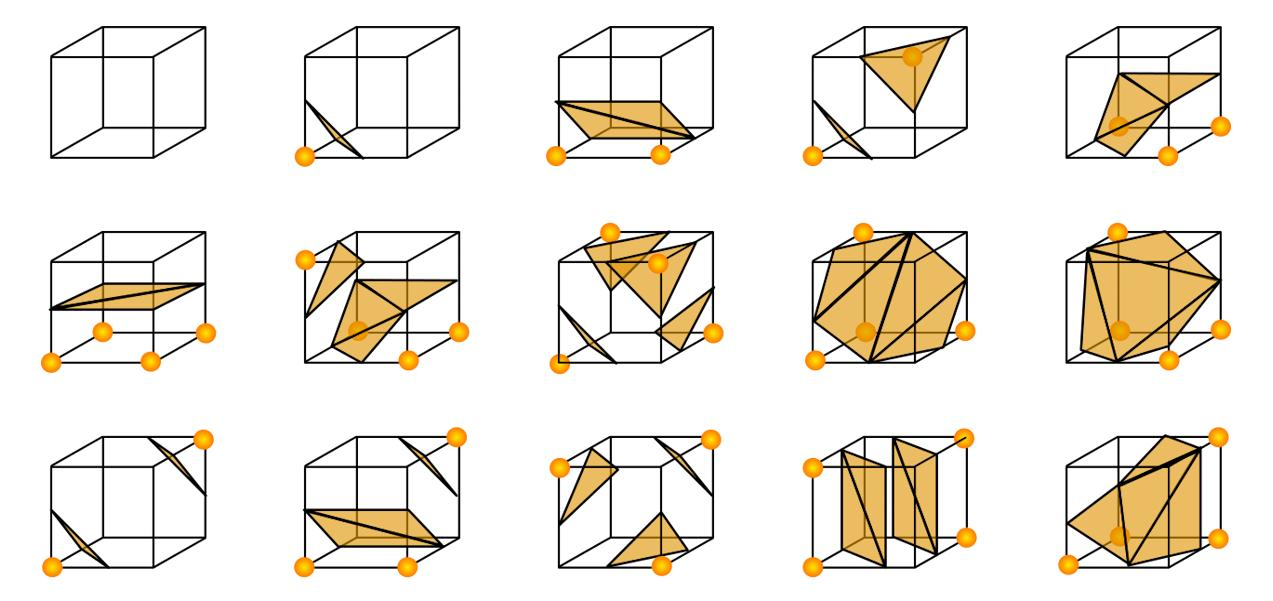

The main idea of voxel hashing is to save memory by storing only the parts of 3D space that the robot actually needs, instead of allocating memory for every voxel in a huge 3D grid.

Dense voxel grid
Memory is allocated for every voxel, even in empty space.


Sparse voxel representation
Memory is allocated only for selected regions containing useful data.


For example, suppose the environment contains 1000 $\times$ 1000 $\times$ 1000 voxels.
The total is:
$$ 1000^3=1,000,000,000 $$

That's one billion voxels.
If we store only 1 million voxels around observed surfaces, we avoid allocating storage for most of the grid.
A clarification: TSDF systems often store voxels in blocks, and some allocate space around surfaces rather than only at the exact occupied voxels.



Your formula is:
$$
h(v)=
(v_xp_1\oplus v_yp_2\oplus v_zp_3)
\bmod n $$

Let's break it down.
- v=(v_x,v_y,v_z): integer coordinates identifying a voxel.
- p_1,p_2,p_3: large constants, often chosen as primes, to mix the coordinates.
- $\oplus$: bitwise XOR operation.
- n: the number of hash-table slots.
- h(v): the slot index where the voxel's data can be stored or looked up.
Important: The hash function does not itself decide whether a voxel is occupied. It computes where to look up the voxel in a hash table.

ICP (Iterative Closest Point) is an algorithm that helps a robot estimate how its camera moved between two frames by aligning 3D points from the two frames.

The basic problem: the camera moves
Imagine a robot observes a wall using its depth camera.
- Frame 1: the camera sees a set of 3D points on the wall.
- Frame 2: the camera moves slightly and sees the same wall from a different position.
The two point clouds won't line up automatically because the camera moved.


ICP estimates a transformation T that aligns the points from the current frame with points from the reference frame.
This transformation has six degrees of freedom:
- Three translations: t_x,t_y,t_z.
- Three rotations: \omega_x,\omega_y,\omega_z, represented locally by a small rotation vector \omega.
Together, these describe the camera's 3D motion.



Your equation is:
$$ \min_T \sum_i
\left((Tp_i-q_i)\cdot\hat n_i\right)^2 $$

Let's understand each term.
- p_i: a source point from the current camera frame.
- q_i: its corresponding point on the reference surface.
- T: the transformation we want to estimate.
- $\hat n_i$: the unit surface normal at the target point q_i.
- $\cdot$: the dot product.

First, transform the source point:
$$ p_i'=Tp_i $$

Then calculate the difference:
$$ e_i=p_i'-q_i $$

This is a 3D error vector. However, point-to-plane ICP measures only the component of this error perpendicular to the target surface, using the surface normal:
$$ r_i=(p_i'-q_i)\cdot\hat n_i $$

The algorithm minimizes the sum of squared residuals $r_i^2$.

Why do we need the small-angle approximation?


The transformation $T$ includes rotation and translation. Rotation involves sine and cosine functions, which make the optimization nonlinear.
Instead of solving for the entire transformation in one step, ICP estimates a small motion correction at each iteration.
The small-angle approximation uses:
$$ \sin\theta\approx\theta,\qquad \cos\theta\approx1 $$

for small $\theta$.
We represent the small rotation using a vector:
$$ \omega=
\begin{bmatrix}
\omega_x\\
\omega_y\\
\omega_z
\end{bmatrix} $$

Its skew-symmetric matrix is:
$$ [\omega]_\times=
\begin{bmatrix}
0&-\omega_z&\omega_y\\
\omega_z&0&-\omega_x\\
-\omega_y&\omega_x&0
\end{bmatrix} $$

This matrix has the useful property that:
$$ [\omega]_\times p=\omega\times p $$

where $\times$ denotes the cross product.
Your approximation
$$ T\approx I+
\begin{bmatrix}
[\omega]_\times&t\\
0&0
\end{bmatrix} $$

is a first-order approximation of a rigid transformation near the identity. More generally, when the current estimate is not the identity, this approximation is applied to a small incremental transformation and composed with the current estimate.

Derive the linear system \(A\xi=b\)
This is the most important mathematical step.
Step 1: Define the six unknowns.
Combine rotation and translation into a six-dimensional vector:
$$ \xi=
\begin{bmatrix}
\omega_x&\omega_y&\omega_z&t_x&t_y&t_z
\end{bmatrix}^{T} $$

These are the six motion corrections we want to estimate.
Step 2: Apply the small transformation to a source point.
For a small motion correction:
$$ p'\approx p+\omega\times p+t $$

The point-to-plane residual becomes:
$$ r\approx
\hat n^T(p-q)
+\hat n^T(\omega\times p)
+\hat n^Tt $$

Using the cross-product identity,
$$ \hat n^T(\omega\times p)
=(p\times\hat n)^T\omega $$

we get:
$$ r\approx
\hat n^T(p-q)
+(p\times\hat n)^T\omega
+\hat n^Tt $$

Step 3: Rearrange into a linear equation.
At the minimum, we want each residual to approach zero:
$$ (p\times\hat n)^T\omega+\hat n^Tt
=-\hat n^T(p-q) $$

Therefore, one row of the linear system is:
$$ \underbrace{
\begin{bmatrix}
(p\times\hat n)^T&\hat n^T
\end{bmatrix}}_{\text{one row of }A}
\underbrace{
\begin{bmatrix}
\omega\\t
\end{bmatrix}}_{\xi}
=
\underbrace{-\hat n^T(p-q)}_{\text{one entry of }b} $$

So, for each point correspondence, we obtain one equation:
$$ A_i\xi=b_i $$

Step 4: Stack equations from many points.
If we have \(N\) point correspondences, stack all \(N\) rows:
$$ A\xi=b $$

Here, \(A\) has \(N\) rows and 6 columns, \(\xi\) has 6 unknowns, and \(b\) has \(N\) entries.
Usually, there are far more than six correspondences, so the system is overdetermined. We solve a least-squares problem:
$$ \boxed{\xi^*=\arg\min_\xi\|A\xi-b\|^2} $$

A common solution, when the system is well-conditioned, is the normal equation:
$$ A^TA\xi=A^Tb $$

In practice, QR or SVD-based least-squares solvers are often preferable to explicitly forming and inverting \(A^TA\), especially when the geometry is poorly conditioned.

This is how the pieces of your 3D reconstruction pipeline fit together:
1. The depth camera captures a new frame.
2. ICP estimates the camera pose relative to the existing map or previous frame.
3. The system uses that pose to transform the new depth measurements into the map's coordinate system.
4. TSDF fusion combines those measurements with existing voxel values.
5. Marching Cubes extracts a surface mesh from the fused TSDF volume.

iMAP — replacing voxels with a neural network
The central idea behind iMAP is that instead of storing a 3D scene explicitly in voxels, represent the scene implicitly using a neural network and learn the scene as the camera moves.


In the previous approach, the robot maintained a voxel grid:
- Each voxel stored a TSDF value and an accumulated weight.
- Depth observations updated those values.
- Marching Cubes extracted a surface from the zero-crossings.


iMAP takes a different approach.

Traditional TSDF map
The scene is represented by values stored at discrete 3D locations. Memory is used to maintain the voxel representation.

iMAP neural map
The scene is encoded in the learned parameters of a neural network. Querying the network at a 3D position estimates properties of the scene there.



The neural network is written as
$$ f_\theta:(x,y,z)\rightarrow(c,\sigma) $$

Here:
- (x,y,z) : a 3D position in the scene.
- c=(r,g,b) : predicted color.
- $\sigma$ : volume density, describing how strongly the region contributes to the rendered image.
- $\theta$ : all the trainable weights and biases of the network.
Important: The network does not directly return a complete image or a mesh for each input point. It returns local scene properties. Rendering combines many such predictions to produce an image

Positional encoding: why transform the coordinates?
You might ask: why not simply feed $(x,y,z)$ directly into the MLP?
A standard MLP can struggle to represent high-frequency detail when given only raw coordinates. Positional encoding helps by giving it sinusoidal features at multiple spatial frequencies.


The formula is:
$$ \gamma(p)=
\left(
\sin(2^0\pi p),\cos(2^0\pi p),
\ldots,
\sin(2^{L-1}\pi p),\cos(2^{L-1}\pi p)
\right) $$

For \(L=10\), each scalar coordinate produces \(2L=20\) features.
For a 3D point, encode each coordinate separately:
$$ \gamma(x,y,z)=
[\gamma(x),\gamma(y),\gamma(z)] $$

Volume rendering: how does the network produce an image?
The network predicts color and density at a 3D point, but a camera pixel represents everything visible along a ray through the scene.
To predict one pixel, we cast a ray:
$$ r(t)=o+td $$

where:
- $o$: camera origin.
- $d$: ray direction through the pixel.
- $t$: distance parameter along the ray.

At each sampled point \(r(t)\), the network predicts:
$$ (c_i,\sigma_i)=f_\theta(r(t_i)) $$

The rendering algorithm combines these predictions to determine the pixel's final color.
What is density $\sigma$ ?

Think of density as how likely the sampled region is to absorb or terminate the ray's visibility.
- Low density: the ray can pass through the region.
- High density: the region contributes strongly and blocks more of what lies behind it.
Density is nonnegative in a standard NeRF, commonly enforced with an activation such as softplus or ReLU.

Your formula is:
$$ T(t)=\exp\left(-\int_{t_n}^{t}
\sigma(r(s))\,ds\right)$$

It represents the fraction of light or visibility that survives traveling from the near point $t_n$ to position $t$, without being absorbed by the volume.
For intuition:
- $T(t)\approx1$: little density has been encountered, so most visibility remains.
- $T(t)\approx0$: much of the ray's visibility has already been absorbed.

Discretized rendering: calculate the pixel color
Computers cannot evaluate the continuous integral exactly for an arbitrary learned scene, so NeRF samples points along each ray.
For sample \(i\), define the interval length:
$$ \delta_i=t_{i+1}-t_i $$

The probability-like contribution of that interval is:
$$ \alpha_i=1-\exp(-\sigma_i\delta_i) $$

Here, \(\alpha_i\) is the interval's opacity.
The weight of sample \(i\) is:
$$ w_i=T_i\alpha_i $$

where
$$ T_i=\exp\left(-\sum_{j=1}^{i-1}\sigma_j\delta_j\right) $$

Therefore,
$$ \hat C(r)=\sum_{i=1}^{N}w_i c_i $$

In other words, each sample contributes its predicted color, weighted by its opacity and by how much visibility survives from earlier samples.

Rendered depth:

How does the network predict distance?
The depth estimate uses the same rendering weights:
$$ \hat D(r)=\sum_{i=1}^{N}w_i t_i $$

This is an illustrative weighted depth sum. Because the weights sum to less than one here, the result is not a normalized weighted average.

Some implementations normalize the depth weights or handle remaining transmittance differently.


The important idea is that the predicted depth comes from the distribution of density along the ray, not simply from the nearest network query.

Joint optimization: how does iMAP learn the scene?
The loss you provided is:
$$\mathcal L=\sum_{r\in\mathcal R}
\left[
\|\hat C(r)-C_{gt}(r)\|_2^2+
\lambda\|\hat D(r)-D_{gt}(r)\|_2^2
\right]$$

It compares two things:

- Color loss: Does the rendered pixel match the observed camera pixel?

- Depth loss: Does the rendered depth match the depth sensor measurement?
The parameter $\lambda$ controls the relative importance of depth compared with color.

The key difference from ordinary NeRF training
In standard NeRF training, camera poses are often assumed known or estimated beforehand. In SLAM, the camera poses themselves are unknown.
iMAP therefore optimizes both:
$$ \theta\leftarrow\theta-\alpha\nabla_\theta\mathcal L $$

and, for a keyframe pose,
$$ \xi_i\leftarrow\xi_i-\alpha\nabla_{\xi_i}\mathcal L $$

The first update improves the neural scene representation.

The second adjusts the camera pose.
This creates a coupled problem: better camera poses help the system build a better map, and a better map helps it estimate camera poses.






Pose representation using $SE(3)$
A camera pose is represented by a rigid transformation:
$$ T=
\begin{bmatrix}
R&t\\
0&1
\end{bmatrix}\in SE(3) $$

Here:
- $R\in SO(3)$ is the $3\times3$ rotation matrix.
- $t\in\mathbb R^3$ is the translation vector.
The pose has six degrees of freedom.
Instead of optimizing the 16 entries of a $4\times4$ matrix independently, the system uses a six-dimensional local parameter:
$$ \xi=
\begin{bmatrix}
\omega\\v
\end{bmatrix}
\in\mathbb R^6 $$

Here, $\omega$ represents rotation and $v$ represents translational motion in the Lie algebra coordinates.
The exponential map converts a local motion update into a valid rigid transformation:
$$ T_{\text{update}}=\exp(\hat\xi) $$

where
$$ \hat\xi=
\begin{bmatrix}
[\omega]_\times&v\\
0&0
\end{bmatrix} $$

For the rotation component, Rodrigues' formula gives:
$$ R=I+\frac{\sin\|\omega\|}{\|\omega\|}[\omega]_\times
+\frac{1-\cos\|\omega\|}{\|\omega\|^2}[\omega]_\times^2 $$

The full $SE(3)$ exponential map also couples rotation and translation through a matrix often called $V$; the translation is generally $Vv$, not simply $v$ for arbitrary finite rotations.
The practical advantage is that pose updates remain consistent with rigid-body geometry.

The complete iMAP pipeline
1. Capture RGB-D frame
Obtain color and depth measurements

2. Sample camera rays
Generate 3D sample positions along selected pixel rays

3. Query the MLP
Predict color and density at sampled positions

4. Render color and depth
Combine predictions using volume-rendering weights

5. Compute loss
Compare rendered results with observed RGB-D data

6. Update scene and camera pose
Optimize neural parameters and pose, then process the next frame

NICE-SLAM: Complete Mathematical Deep Dive
1. WHY NICE-SLAM EXISTS — The iMAP Problem First

Before the math, understand what broke in iMAP:

iMAP uses ONE MLP for the whole scene:

$$f_\theta : \gamma(x,y,z) \rightarrow (c, \sigma)$$

When you update for new room → gradients overwrite weights → old room forgotten

This is Catastrophic Forgetting:

$$\theta_{t+1} = \theta_t - \alpha \nabla_\theta \mathcal{L}_{new}$$

The gradient $\nabla_\theta \mathcal{L}_{new}$ has no awareness of old scenes — it just overwrites.

NICE-SLAM's fix: tie memory to spatial location, not network weights.

Instead of forcing one neural network to remember the entire 3D scene, store scene features in a hierarchy of spatial grids and use small neural networks to interpret those features.
Let's connect this to the two approaches you already learned.
- TSDF: Stores signed distances explicitly in voxels.
- iMAP: Stores the scene in the weights of one shared MLP.
- NICE-SLAM: Stores learned features in multi-resolution grids, with neural decoders that turn those features into scene properties.

Hierarchical feature grids: coarse, medium and fine
Your equation is:
$$\Phi=\{\Phi_c,\Phi_m,\Phi_f\}$$

Here, each $\Phi$ is a grid of learnable feature vectors, rather than simply a grid of TSDF values.


Coarse grid — $\Phi_c$
Global structure
Stores low-resolution information about large structures, such as room layout and broad surfaces.


Medium grid — $\Phi_m$
Intermediate detail
Represents smaller geometric structures that the coarse grid cannot capture well.


Fine grid — $\Phi_f$
Local detail
Represents finer geometry and, in the feature hierarchy, detailed local information.



Think of mapping a room.
The coarse grid learns where the walls are. The medium grid captures the shape of a desk. The fine grid helps represent details such as the desk's thin edges.
The grids work together, so the system can model different spatial scales without making a single representation responsible for every detail.

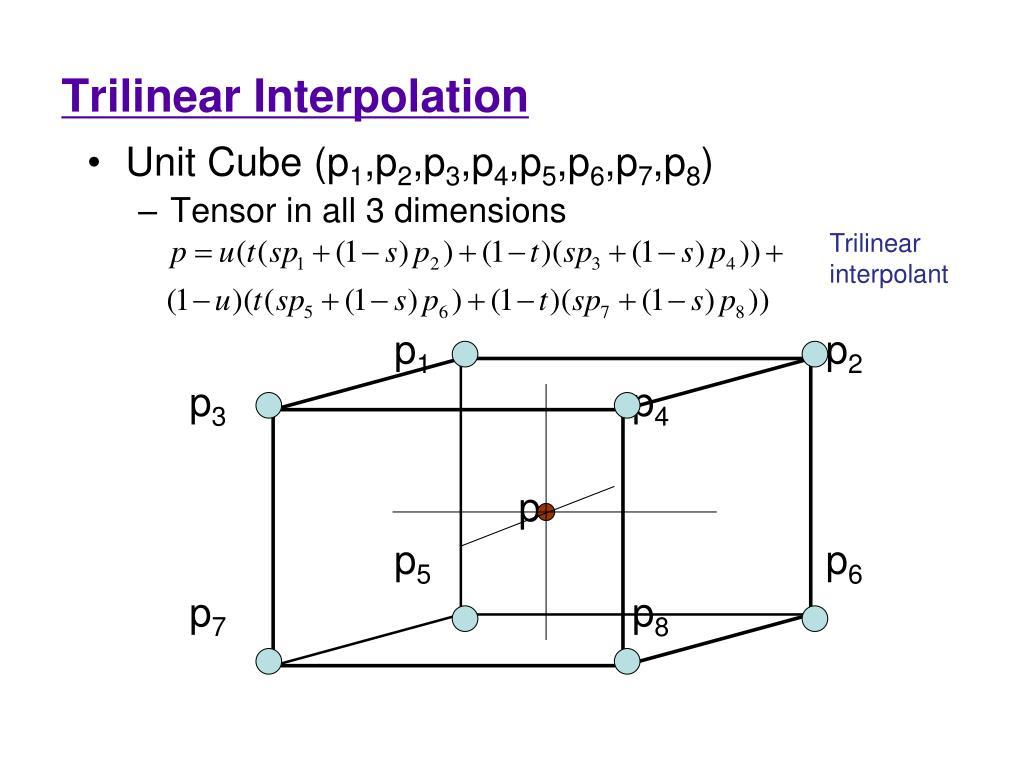

Trilinear interpolation: how do we obtain a feature at an arbitrary point?


A feature grid stores values at discrete grid locations. But a camera ray can pass through any 3D position, not just the grid corners.


Suppose a ray sample lies between eight neighboring grid vertices.

Let the fractional position within the cell be:
$$ (\alpha,\beta,\gamma)\in[0,1]^3 $$

These indicate the sample's relative position along the cell's three axes.
For example:
- $\alpha=0$: at the lower side along the $x$-axis.
- $\alpha=1$: at the upper side along the $x$-axis.
- $\alpha=0.5$: halfway along that axis.
The feature at the sample position is interpolated from the eight corners:
$$ \phi(x)=
\sum_{i=0}^{1}\sum_{j=0}^{1}\sum_{k=0}^{1}
w_{ijk}\Phi[v+(i,j,k)] $$

The weight for each corner is the product of three one-dimensional interpolation weights:
$$ \begin{aligned}
w_{ijk}={}&
\big(i\alpha+(1-i)(1-\alpha)\big)\\
&\cdot\big(j\beta+(1-j)(1-\beta)\big)\\
&\cdot\big(k\gamma+(1-k)(1-\gamma)\big)
\end{aligned} $$

This is equivalent to your absolute-value formula for $\alpha,\beta,\gamma\in[0,1]$.

Occupancy decoding: how do features become geometry?
After interpolation, each grid gives a feature vector at the queried position:
$$ \phi_c(x),\quad\phi_m(x),\quad\phi_f(x) $$

These are combined and passed to a small decoder network:
$$ o(x)=f_\theta(\phi_c(x),\phi_m(x),\phi_f(x)) $$

In your simplified occupancy formulation, $o(x)\in[0,1]$ represents how likely the point is to belong to occupied geometry.
For example:
- $o(x)=0.05$: likely free space.
- $o(x)=0.50$: uncertain or intermediate occupancy.
- $o(x)=0.95$: likely occupied.
These are illustrative interpretations, not guaranteed calibrated probabilities.
Color is predicted separately:
$$ c(x)=g_\phi(\phi_f(x),d) $$

Here, $d$ is the viewing direction.

The color decoder uses the fine-scale feature and viewing direction to predict RGB color.


The important distinction is that the grids store features, while the decoders interpret those features.


A technical clarification: the original NICE-SLAM formulation is primarily based on an implicit signed-distance function (SDF) for geometry, rather than exactly the occupancy-decoder formulation in your notes.

Your equations are a useful simplified way to understand grid-based neural scene representations, but they are not a precise reproduction of every part of the original method.

Volume rendering: connecting the geometry to camera pixels
Your notes give:
$$ \sigma(x)=\frac{o(x)}{\delta} $$


Here, $\delta$ is the length of a ray-sampling interval.


This formula attempts to convert occupancy into a density for volume rendering. The intuition is that occupancy estimates how much geometry exists in a region, while density determines how strongly that region affects the ray.
However, this is a simplified conversion, not a universal occupancy-to-density rule. Standard volume rendering usually derives interval opacity from density as
$$ \alpha_i=1-e^{-\sigma_i\delta_i} $$

Then the renderer uses the sample's opacity and transmittance to combine colors and estimate depth, just as in the NeRF/iMAP approach.
The rendering principle stays similar; the main change is how the scene properties are represented and queried.

Local updates: how does NICE-SLAM address catastrophic forgetting?
This is one of the most important ideas in your notes.
Recall the problem with iMAP: one shared MLP represents the entire scene. Updating it with new observations can damage geometry learned from earlier observations.



NICE-SLAM instead uses spatially organized feature grids, allowing updates to be localized.


The equation is:
$$ \mathcal V_{\text{update}}=
\{v:\|v-x_{\text{obs}}\|_\infty<r\} $$


$v$: a voxel or grid location.


$x_{\text{obs}}$: the location associated with a new observation.

$r$: the spatial neighborhood radius.

$\|\cdot\|_\infty$: the maximum absolute coordinate difference.




Intuition: If the robot observes a new chair leg, it should update the relevant region instead of unnecessarily changing the entire representation of the room.


Spatially localized features reduce interference between distant regions.

But local updating alone does not mathematically guarantee that catastrophic forgetting can never happen; the loss, optimization strategy, and shared decoder parameters also matter.



Mapping loss: what does the robot learn from?
Your mapping objective is:
$$
\mathcal L_{\text{map}}=
\sum_r\left[
\lambda_1\mathcal L_{\text{RGB}}+
\lambda_2\mathcal L_D+
\lambda_3\mathcal L_{\text{fs}}+
\lambda_4\mathcal L_{\text{empty}}
\right] $$

Each term serves a different purpose.

$\mathcal L_{\text{RGB}}$	Make rendered colors match the observed image.


$\mathcal L_D$	Make rendered geometry or depth agree with sensor measurements.


$\mathcal L_{\text{fs}}$	Penalize occupancy predicted in known free space.

$\mathcal L_{\text{empty}}$	In your equation, encourage occupancy near one at selected near-surface samples.


For the free-space loss,
$$
\mathcal L_{\text{fs}}=\sum_{x\in\text{freespace}}o(x)^2 $$

if $o(x)=0.9$, the penalty is $0.81$. If $o(x)=0.1$, the penalty is $0.01$. So the model is encouraged to predict low occupancy in free space.
Your near-surface term is
$$
\mathcal L_{\text{empty}}=
\sum_{x\in\text{near-surface}}(o(x)-1)^2 $$

This actually encourages occupancy to approach one near the surface.

The name “empty” is therefore misleading under this definition.


Also, these occupancy losses are illustrative; the original NICE-SLAM uses an SDF-based geometry formulation and associated supervision rather than precisely these two occupancy terms.

Why is NICE-SLAM still slow?
NICE-SLAM improves the scene representation, but it still has to perform substantial computation.

Three grid lookups
Each queried 3D position may require interpolation at coarse, medium, and fine resolutions.



Ray marching
A pixel still requires sampling multiple positions along its camera ray. If there are 32 samples, the scene must be queried at those 32 locations.



Neural decoding and optimization
Feature interpolation, decoder evaluations, rendering, and gradient updates all consume computation.



The exact speed depends on hardware, implementation, scene size, sampling strategy, and image resolution. NICE-SLAM is not inherently limited to 32 samples per ray or incapable of full-image rendering; those numbers are configuration-dependent.

ESLAM — explained step by step
The main idea of ESLAM is to represent a 3D scene using three sets of 2D feature planes instead of storing features in a full 3D grid.

Then it uses those features to predict the scene's Signed Distance Function (SDF) and render images or depth maps.


NICE-SLAM: stores learnable features in hierarchical 3D grids.

ESLAM: stores learnable features in multi-scale 2D planes and combines them to represent 3D geometry.



Now imagine three 2D planes, each containing \(n\times n\) locations:
$$ N_{\text{planes}}=3n^2 $$

How do the three planes represent a 3D point?
Suppose a 3D point is:
$$ x=(2.4,\;3.2,\;1.7) $$

ESLAM projects this point onto three planes.
Plane	Coordinates used	Feature retrieved

XY	$(2.4,3.2)$	$f^{xy}(x)$

XZ	$(2.4,1.7)$	$f^{xz}(x)$


YZ	$(3.2,1.7)$	$f^{yz}(x)$


Each plane provides a different view of the point's location.

Then concatenate the features:

$$ f(x)=[f^{xy}(x)\;||\;f^{xz}(x)\;||\;f^{yz}(x)] $$

Here, $||$ means concatenation — placing feature vectors next to one another.


For example, if each plane returns a 4-dimensional feature vector, the combined feature has $4+4+4=12$ values.


Intuition: The XY plane provides information about horizontal layout, the XZ plane provides another spatial view, and the YZ plane provides a third. Together, these features help the decoder distinguish locations in 3D.


However, the planes do not guarantee a unique representation of every possible scene by themselves. The decoder learns how to combine their features, and multiple scales and coordinate encoding provide additional information.

Bilinear interpolation — how do we retrieve a feature?
A query point will usually fall between grid locations. We therefore interpolate its feature from the four neighboring grid points.

Suppose the point is 25% of the way across the cell and 40% of the way down:
$$ \alpha=0.25,\qquad \beta=0.40 $$

The weights are:
$$ \begin{aligned}
w_{00}&=(1-\alpha)(1-\beta)=0.45\\
w_{10}&=\alpha(1-\beta)=0.15\\
w_{01}&=(1-\alpha)\beta=0.30\\
w_{11}&=\alpha\beta=0.10
\end{aligned} $$

Notice that all weights add up to 1.
For a simple numerical example, suppose the four neighboring feature values are 2, 6, 4 and 10, respectively. Then:
$$ \begin{aligned}
f(u,v)={}&0.45(2)+0.15(6)\\
&+0.30(4)+0.10(10)\\
={}&3.8
\end{aligned} $$

The interpolated value is 3.8. In the actual network, each corner contains a vector of learned features rather than just one number.
Why is this useful? The feature changes smoothly as the query point moves through space. This is important because camera poses and 3D points change continuously during SLAM optimization.

The feature planes provide learned spatial features, but ESLAM also appends coordinate encoding:
$$
\hat f(x)=[f(x)\;||\;\gamma(x)]
$$

The positional encoding $\gamma(x)$ represents coordinates using sine and cosine functions at different frequencies.
For example, it may contain terms such as:
- $\sin(2^k\pi x)$
- $\cos(2^k\pi x)$
with corresponding terms for $y$ and $z$.



Low frequencies help describe broad spatial variation; higher frequencies allow the network to represent rapid changes, such as thin edges or fine surface details.

The combined representation gives the decoder both learned features from the planes and explicit information about the point's coordinates.

ESLAM uses \(L\) resolutions. At each resolution \(l\), it retrieves features from that level's three planes:
$$ f^l(x)=\operatorname{Interp}(F^l,\operatorname{proj}(x)) $$

The features from all levels are concatenated:
$$ f(x)=f^1(x)||f^2(x)||\cdots||f^L(x) $$

Think of the levels as different map resolutions:
- Coarse: broad room layout and large surfaces.
- Medium: furniture and other objects.
- Fine: smaller structures and surface details.


These are intuitive roles, not strict guarantees that each level learns only one type of structure.
Why not just use a fine grid? A fine grid everywhere can consume more memory, while coarse grids alone cannot capture small details. Multiple resolutions balance these competing needs.

SDF decoding — predicting distance to a surface
Now the decoder takes the combined feature and predicts a scalar:
$$ s(x)=f_\theta(\hat f(x)) $$


This scalar is the Signed Distance Function (SDF) value.


An SDF represents the signed distance from a point to the scene surface.

A common convention is:

$s(x)>0$	Outside the surface

$s(x)=0$	On the surface

$s(x)<0$	Inside the surface.

For example, under this convention, $s(x)=0.2$ means the point is 0.2 distance units outside the surface, while $s(x)=-0.1$ means it is 0.1 units inside.


The zero level set, $s(x)=0$, describes the reconstructed surface.


Unlike a simple occupancy prediction, which asks whether a location is occupied, an SDF predicts signed distance.

That gives the network more geometric information about how far a point is from the surface.

Why convert SDF to density?

Neural rendering needs a density value along each camera ray.

ESLAM can convert the SDF into density using the formula in your notes:
$$ \sigma(s)=\frac{1}{\beta}
\operatorname{Sigmoid}\left(\frac{-s}{\beta}\right)
\operatorname{Sigmoid}\left(\frac{s}{\beta}\right) $$

where
$$ \operatorname{Sigmoid}(z)=\frac{1}{1+e^{-z}} $$

and $\beta$ controls the sharpness of the surface representation.


The important property is that density is highest near $s=0$ and decreases as the point moves away from the surface in either direction.



1.   3D query point $x=(x,y,z)$
2.   Project onto XY, XZ and YZ feature planes
3.   Bilinear interpolation at multiple scales
4.   Concatenate features and positional encoding


1.   Neural decoder predicts SDF
2.   Convert SDF to density and render camera rays


3D Gaussian Splatting (3DGS) — from neural fields to fast rendering


The big conceptual change is this:
iMAP, NICE-SLAM and ESLAM query a scene representation at many points along camera rays.

3D Gaussian Splatting instead represents the scene as a collection of explicit, learnable 3D blobs and projects those blobs onto the image.

That changes how rendering works and makes highly efficient GPU rendering possible.



3D Gaussian Splatting
Instead of repeatedly asking a neural network what exists at each sample point, 3DGS stores explicit scene elements called Gaussians.

It projects visible Gaussians onto the image plane and rasterizes their contributions.


The two rendering pipelines
Neural field: ray marching
Camera → many rays → many 3D sample points → query representation → combine samples


3DGS: splatting
Stored 3D Gaussians → project to 2D → sort by depth → rasterize and blend


One important correction to the shorthand in your notes: 3DGS is not literally one operation or one pass over all Gaussians.

It still projects Gaussians, identifies affected tiles, sorts overlapping contributions, and blends them.

The speed advantage comes from efficient rasterization and avoiding dense ray sampling and repeated MLP evaluations at every sample.


Also, the Gaussians are explicit scene primitives; the original 3DGS renderer does not need an MLP query for every pixel sample.

What exactly is a 3D Gaussian?
Each Gaussian $k$ is represented by:
$$ \mathcal G_k=\{\mu_k,\Sigma_k,o_k,c_k\} $$

Think of a Gaussian as a soft, fuzzy ellipsoid in 3D space.


Center — $ \mu_k$
$ \mu_k=(x,y,z)$ specifies where the Gaussian is located in the world.

Shape and orientation — $ \Sigma_k$
The covariance matrix controls how wide, narrow, and rotated the ellipsoid is.

Opacity — $ o_k$
Controls how strongly the Gaussian contributes to the image. In your formulation, it lies between 0 and 1.

Color — $ c_k$
The Gaussian has learned color parameters, often spherical-harmonic coefficients that let its apparent color vary with viewing direction.



Unlike a point cloud, which mainly stores points, a Gaussian also has a spatial extent and a soft contribution. Unlike a voxel grid, it does not need to allocate a feature vector at every location in a dense 3D lattice.

Covariance decomposition — how do we guarantee a valid ellipsoid?
Your notes give:
$$ \Sigma=RSS^TR^T $$

Here:
- $ R$  is a rotation matrix.
- $ S=\operatorname{diag}(s_x,s_y,s_z)$  is a scaling matrix.
- $ s_x,s_y,s_z$  control the ellipsoid's dimensions.
Because $ S$  is diagonal,
$$ SS^T=
\begin{bmatrix}
s_x^2&0&0\\
0&s_y^2&0\\
0&0&s_z^2
\end{bmatrix} $$

Therefore,
$$ \Sigma=R
\begin{bmatrix}
s_x^2&0&0\\
0&s_y^2&0\\
0&0&s_z^2
\end{bmatrix}
R^T $$

This construction guarantees that $ \Sigma$  is positive semidefinite, because for any vector $ v$ ,
$$ v^T\Sigma v
=(R^Tv)^TSS^T(R^Tv)
=\|S^TR^Tv\|^2\geq0 $$


Why does that matter?

Covariance describes valid spatial spread.

A negative variance would be physically meaningless and could make Gaussian evaluation invalid.


How is it optimized?

Rather than directly changing the nine entries of $\Sigma$, the model learns the three scales and a rotation parameterized by a quaternion.

The quaternion is normalized to represent a valid rotation, and scales are commonly parameterized to remain positive.


The optimizer can then stretch, shrink, and rotate the ellipsoid while preserving a valid covariance matrix.

Spherical harmonics — why does color depend on viewing direction?
A Gaussian's color can depend on the direction from which the camera sees it:
$$
c(\mathbf d)=
\sum_{l=0}^{L}\sum_{m=-l}^{l}
k_l^mY_l^m(\mathbf d)
$$

Let's decode that expression.
- $\mathbf d$: viewing direction.
- $Y_l^m(\mathbf d)$: a spherical-harmonic basis function evaluated at that direction.
- $k_l^m$: learned coefficient controlling the contribution of that basis function.
- $L$: maximum spherical-harmonic degree.


You can think of spherical harmonics as a collection of smooth patterns defined over directions in 3D.


A constant color can be represented by the lowest-order term.

 Higher orders let the model represent more complicated directional changes, such as the appearance of highlights.

For example, a shiny object may look brighter from one angle than another.

View-dependent color gives 3DGS some ability to reproduce that effect without storing a completely separate color for every possible camera direction.


This is an approximation of appearance, not a complete physical simulation of light.

Projecting a 3D Gaussian into 2D


This is one of the most important mathematical steps.

A 3D Gaussian lives in world space, but the final image is 2D. We need to determine what shape that Gaussian appears to have on the camera's image plane.

Step 1: Transform the Gaussian into camera coordinates.


Let $W$ denote the camera's linear world-to-camera rotation component.

Its center is transformed into camera coordinates before projection.


The covariance in camera coordinates becomes:


$$ \Sigma_{\text{cam}}=W\Sigma W^T $$
Translation changes the center but does not directly change covariance.


Step 2: Apply perspective projection


For a point in camera coordinates $(x,y,z)$, its image coordinates are:

$$ u=f_x\frac{x}{z}+c_x $$

$$ v=f_y\frac{y}{z}+c_y $$


Here $f_x,f_y$ are focal lengths, while $c_x,c_y$ are the image center offsets.


Perspective projection is nonlinear because of division by $z$.

3DGS locally approximates it as a linear transformation around the Gaussian's center.


The Jacobian of that local approximation is:


$$ J=
\begin{bmatrix}
f_x/z&0&-f_xx/z^2\\
0&f_y/z&-f_yy/z^2
\end{bmatrix} $$


Each entry describes how a small change in a 3D coordinate changes the projected image coordinates.


Step 3: Transform the covariance
The projected covariance is:


$$ \Sigma_{2D}=JW\Sigma W^TJ^T $$


Dimensions confirm that this works:


$$ (2\times3)(3\times3)(3\times2)
=2\times2 $$


The resulting matrix is:


$$ \Sigma_{2D}=
\begin{bmatrix}
\sigma_u^2&\sigma_{uv}\\
\sigma_{uv}&\sigma_v^2
\end{bmatrix} $$


It describes the Gaussian's spread and orientation in image coordinates.


A subtle but important detail: we do not simply drop the third row and column of the original 3D covariance.

 We transform the covariance through the projection Jacobian; that transformation produces the 2D covariance.

Evaluating the Gaussian at a pixel


After projection, the Gaussian has a 2D center $\mu'$ and covariance $\Sigma'$.
At pixel location $p$, its contribution is:

$$
\alpha_k(p)=o_k
\exp\left(
-\frac12(p-\mu_k')^T
{\Sigma_k'}^{-1}
(p-\mu_k')
\right)
$$

The expression inside the exponential is related to the squared Mahalanobis distance from the pixel to the Gaussian center.
Intuitively:
- At the center, the exponent is zero, so the exponential equals 1.
- As you move away from the center, the exponential decreases.
- Pixels far outside the Gaussian's footprint receive negligible contribution.
At the center, $p=\mu_k'$, so:
$$
\alpha_k(\mu_k')=o_k
$$

The contribution at the center is therefore the Gaussian's opacity.


The Gaussian is not a hard-edged ellipse.

 It has a smoothly decreasing influence, although practical renderers truncate its footprint to avoid spending time on negligible contributions.

Alpha blending — combining Gaussians into a pixel


A pixel may be covered by several Gaussians.

Their colors must be combined in depth order, from front to back.


Define the transmittance before Gaussian $k$ as:

$$ T_k=\prod_{j=1}^{k-1}(1-\alpha_j) $$

This tells us how much of the pixel's contribution remains available after the preceding Gaussians.

The color is:

$$ C(p)=\sum_{k=1}^{K}T_k\alpha_k(p)c_k $$

The same weighting can be used for a depth estimate:

$$ D(p)=\sum_{k=1}^{K}T_k\alpha_k(p)d_k $$

where $d_k$ is the depth associated with Gaussian $k$.

Tile-based rasterization — why divide the screen into tiles?


Rendering every Gaussian against every pixel would be wasteful.

Most Gaussians affect only a small part of the image.


3DGS therefore divides the screen into small tiles, commonly $16\times16$ pixels in the implementation described by your notes.


The process is:

1. Project each Gaussian and estimate its 2D footprint.

2. Compute a bounding box around the footprint.

3. Find the tiles overlapped by that bounding box.

4. Generate entries associating Gaussians with those tiles.

5. Sort entries by tile and depth.

6. Process each tile's relevant Gaussians on the GPU, blending their contributions for each pixel.


The tile assignment in your notes can be written as:
$$ \text{tiles}(k)=
\left\{(u,v):
\operatorname{bbox}(\mu'_k,3\sigma'_k)
\cap\operatorname{tile}(u,v)\ne\emptyset
\right\} $$

The $3\sigma$ notation is an intuitive approximation to the footprint:
a Gaussian's influence is very small several standard deviations from its center.

Actual implementations use projected bounds and practical cutoffs.


The sorting key groups entries by tile ID and then depth:

$$ \text{key}_k=
(\text{tile_id}\ll32)
\mid\text{depth_bits}(z_k) $$

Here, << denotes a bit shift and | denotes bitwise OR.

This describes a packed sorting key conceptually; actual implementations use specific encodings and sorting details.


GPU radix sort can efficiently order these entries, allowing many tiles to be processed in parallel.

### Tile-based rasterization — actual implementation in 3DGS

The original 3DGS implementation uses CUDA and NVIDIA's CUB library.

1\. Project each Gaussian: Compute its 2D mean, covariance, and screen-space radius.

2\. Calculate tile bounds: Use the projected radius and `getRect()` to find the rectangular range of overlapping tiles.

3\. Count tile entries: Count how many tiles each Gaussian touches and use a prefix sum to allocate output positions.

4\. Duplicate references: The `duplicateWithKeys` kernel creates one entry per overlapping tile, storing the tile ID, depth, and Gaussian index.

5\. Sort entries: Use `cub::DeviceRadixSort::SortPairs()` to group entries by tile ID and order them by depth within each tile.

6\. Identify tile ranges: The `identifyTileRanges` kernel records the start and end of each tile's entries in the sorted list.

7\. Rasterize and blend: CUDA thread blocks process each tile's pixels, blending relevant Gaussians front to back using alpha compositing.

Actual implementation: `rasterizer_impl.cu`, with kernels such as `duplicateWithKeys` and `identifyTileRanges`, and CUB's radix sort and prefix-sum operations.

Source: [Official 3DGS repository](https://github.com/graphdeco-inria/gaussian-splatting/tree/main/submodules/diff-gaussian-rasterization/cuda_rasterizer?utm_source=chatgpt.com).

GS-SLAM — putting 3D Gaussian Splatting into a SLAM system

You now have the rendering representation from 3DGS.

GS-SLAM adds the pieces needed for simultaneous localization and mapping (SLAM): tracking the camera, updating the 3D map, deciding when to add or remove Gaussians, and optimizing everything from image and depth errors.


The central loop is:


1. Receive RGB-D frame
Color image + measured depth

2. Track camera pose
Find the camera position and orientation that best explain the frame

3. Render the Gaussian map
Predict color and depth from the current pose

4. Compute losses and optimize
Compare predicted images with the observations

5. Update the map
Add useful Gaussians, refine existing ones, and prune poor ones

6. Repeat for the next frame



Full system loss — how do we measure reconstruction quality?
The total loss is:

$$ \mathcal L_{\text{total}}
=\lambda_1\mathcal L_{\text{RGB}}
+\lambda_2\mathcal L_D $$

There are two main objectives.
- $\mathcal L_{\text{RGB}}$: make the rendered image resemble the camera's observed image.


- $\mathcal L_D$: make the rendered depth resemble the measured depth.


The weights $\lambda_1,\lambda_2$ control the relative influence of color and depth.


1.1 RGB loss: L1 plus SSIM
Your notes define:

$$ \mathcal L_{\text{RGB}}
=(1-\lambda_{\text{ssim}})\mathcal L_1^{\text{RGB}}
+\lambda_{\text{ssim}}\mathcal L_{\text{SSIM}} $$

The L1 image loss is the mean or sum of absolute pixel differences, depending on the implementation:

$$ \mathcal L_1^{\text{RGB}}
\propto \sum_p|\hat C(p)-C_{\text{gt}}(p)| $$

Here, $\hat C(p)$ is the rendered pixel and $C_{\text{gt}}(p)$ is the observed pixel.


For example, if the observed pixel intensity is 100 and the rendered intensity is 92, the absolute error is:

$$ |100-92|=8 $$

L1 penalizes the size of the difference directly.


But a pixelwise loss doesn't fully describe whether two image patches have similar structure.

 That's why your notes include SSIM.



1.2 SSIM — compare local image structure
SSIM stands for Structural Similarity Index Measure.

It compares local luminance, contrast, and structure.
Your equation is:

$$ SSIM(x,y)=
\frac{(2\mu_x\mu_y+C_1)(2\sigma_{xy}+C_2)}
{(\mu_x^2+\mu_y^2+C_1)
(\sigma_x^2+\sigma_y^2+C_2)} $$

where:
- $\mu_x,\mu_y$: local mean intensities.
- $\sigma_x^2,\sigma_y^2$: local variances.
- $\sigma_{xy}$: local covariance.
- $C_1,C_2$: small stabilizing constants.
The loss is:

$$ \mathcal L_{\text{SSIM}}=1-SSIM(x,y) $$

For similar image patches, SSIM is close to 1, so the loss is close to 0.

For dissimilar patches, SSIM tends to decrease and the loss increases.

The distinction is important: L1 measures direct pixel errors, while SSIM encourages the local structures and contrast patterns to agree.


1.3 Depth loss

$$ \mathcal L_D=\|\hat D-D_{\text{gt}}\|_1 $$

At each pixel, compare the rendered depth with the sensor's depth.

Depth supervision helps constrain geometry and camera position, while RGB supervision helps constrain appearance and alignment.


Why use both? A scene might look approximately correct in color but have incorrect depth.

Conversely, a geometrically plausible reconstruction may still have poor colors. The combined objective penalizes both problems.

Adaptive Gaussian management — when should the map change?
A Gaussian map needs more than optimization of existing parameters. It must also decide when the current collection of Gaussians is insufficient.
Your notes describe three operations:
- Add: introduce Gaussians where the current map fails to explain observations.
- Optimize: adjust existing positions, shapes, opacity, and colors.
- Delete: remove Gaussians that are unhelpful or problematic.
2.1 Adding a Gaussian using depth residuals
The depth residual is:

$$ \epsilon_D(p)=|\hat D(p)-D_{\text{gt}}(p)| $$

Suppose the camera measures a point at 2.0 m, but the current map predicts 3.0 m:

$$ \epsilon_D(p)=|3.0-2.0|=1.0\text{ m} $$

If this exceeds an addition threshold, the system may decide that the map needs additional geometry around this observation.
The new Gaussian center can be initialized by back-projecting the pixel:

$$ \mu_{\text{new}}=\pi^{-1}(p,D_{\text{gt}}(p)) $$

For a pixel $(u,v)$, depth $d$, and camera intrinsics $f_x,f_y,c_x,c_y$, the camera-coordinate point is:

$$ X=d\frac{u-c_x}{f_x} $$


$$ Y=d\frac{v-c_y}{f_y} $$


$$ Z=d $$

Therefore:

$$ \mu_{\text{camera}}=(X,Y,Z) $$

If the Gaussian map is stored in world coordinates, transform this point using the camera-to-world pose:

$$ \mu_{\text{world}}=T_{\text{camera}\rightarrow\text{world}}
\begin{bmatrix}X\\Y\\Z\\1\end{bmatrix} $$

This distinction matters: back-projection initially gives a point in camera coordinates; it must be transformed into the map's coordinate frame if that is where the Gaussians are stored.
The initial covariance in your notes is isotropic:

$$ \Sigma_{\text{new}}=
\begin{bmatrix}
\sigma_{\text{init}}^2&0&0\\
0&\sigma_{\text{init}}^2&0\\
0&0&\sigma_{\text{init}}^2
\end{bmatrix} $$

This creates a spherical Gaussian before optimization reshapes it.
Important limitation: a large depth residual does not necessarily mean missing geometry. It could result from an incorrect camera pose, sensor noise, occlusion, or a moving object. Practical systems need suitable validity checks and management rules rather than blindly adding a Gaussian at every high-error pixel.
2.2 Deleting poor Gaussians
Your notes specify:

$$ \text{delete }\mathcal G_k
\quad\text{if}\quad
o_k<\tau_{\text{delete}}
\quad\text{or}\quad
\|\Sigma_k\|>\tau_{\text{size}} $$

The intuition is:
- Low opacity: the Gaussian contributes very little to the rendered image.
- Excessive size: the Gaussian may have expanded too much or become an unhelpful representation.


The size test is only an example of a pruning rule. In practice, the size metric and threshold must be defined, and a large Gaussian is not automatically bad: a large, flat Gaussian might legitimately represent a wall.


Pruning helps prevent the map from accumulating too many redundant or unstable primitives.

**Coarse-to-fine camera tracking**


Now imagine the camera moves between two frames. The map already contains thousands or millions of Gaussians, but the system doesn't know the new camera pose exactly.

It must estimate a transformation $T$ that aligns the map's rendered view with the new camera observation.
Your notes divide this into two stages.

**Step 1 — Coarse tracking**
Downsample the image and use a selected subset of reliable Gaussians. Optimize an approximate camera pose cheaply.

**Step 2 — Fine tracking**
Initialize from the coarse pose and refine it using full-resolution observations and a broader Gaussian set.



Mathematically, the coarse stage is:

$$ \hat T_{\text{coarse}}=
\arg\min_T
\mathcal L_{\text{track}}^{\text{low-res}}
(T,\mathcal G_{\text{reliable}}) $$


The fine stage is:

$$ \hat T_{\text{fine}}=
\arg\min_T
\mathcal L_{\text{track}}^{\text{full-res}}
(T,\mathcal G_{\text{all}}) $$

The coarse result initializes the fine optimization.

**Why select Gaussians by opacity?**


$$ \mathcal G_{\text{reliable}}
=\operatorname{TopK}(\{o_k\},M) $$

This selects the \(M\) Gaussians with the highest opacity.

High opacity can be a useful heuristic because those Gaussians may have a strong influence on rendered pixels.

But opacity alone does not guarantee reliability: a high-opacity Gaussian could still be misplaced or represent a dynamic object.

Real implementations may use additional criteria.


Coarse-to-fine tracking is a strategy, not a requirement of every GS-SLAM implementation.

**Pose updates on the SE(3) manifold**
This connects directly to the pose optimization and Lie algebra concepts from your earlier ICP studies.


A rigid camera pose contains:
- Three translation degrees of freedom.
- Three rotation degrees of freedom.
Together they form a transformation in $SE(3)$, the group of 3D rigid-body transformations.
A pose can be written as:


$$T=
\begin{bmatrix}
R&t\\
0&1
\end{bmatrix} $$

where $R$ is a $3\times3$ rotation matrix and $t$ is a 3D translation vector.


Instead of independently changing all entries of $R$, we express a small pose update using a six-dimensional vector:


$$\xi=
\begin{bmatrix}
\omega\\v
\end{bmatrix}
\in\mathbb R^6 $$

Here, $\omega$ represents the rotational increment and $v$ represents the translational component of the twist.


The corresponding matrix in the Lie algebra $\mathfrak{se}(3)$ is:


$$[\xi]_\times=
\begin{bmatrix}
[\omega]_\times&v\\
0&0
\end{bmatrix} $$

The skew-symmetric matrix is:


$$[\omega]_\times=
\begin{bmatrix}
0&-\omega_3&\omega_2\\
\omega_3&0&-\omega_1\\
-\omega_2&\omega_1&0
\end{bmatrix} $$

It has the useful property that:


$$[\omega]_\times a=\omega\times a $$

for any 3D vector $a$.
Why use the exponential map?
Your update rule is:


$$T_{t+1}=T_t\exp(\alpha[\xi^*]_\times) $$

This is the precise matrix form of the pose update; shorthand notation often writes $\exp(\alpha\xi^*)$.


The exponential map converts a six-dimensional local motion increment into a valid rigid transformation.

Consequently, the updated rotation remains a proper rotation rather than an arbitrary matrix.


How is the update chosen?
Your notes give:


$$\xi^*=-\frac{\partial\mathcal L}{\partial\xi} $$

This communicates the idea of moving opposite to the loss gradient, but it is incomplete as a general update formula.


A simple gradient-descent step is:


$$\xi^*=-\eta\frac{\partial\mathcal L}{\partial\xi} $$

where $\eta$ is a step size.


Other optimizers, such as Gauss–Newton or Levenberg–Marquardt, can compute the increment differently.


The pose update then applies the resulting increment through the exponential map.


Connection to ICP: both ICP and Gaussian-based tracking adjust a six-degree-of-freedom camera pose to reduce alignment error.

ICP commonly builds geometric point correspondences and residuals; GS-SLAM can optimize a differentiable image-rendering loss.

**Gradient flow through splatting — how does the map learn?**

This is the key connection between rendering and optimization.

A Gaussian has parameters such as:


$$\mu_k,\quad \Sigma_k,\quad o_k,\quad c_k $$

The renderer uses those parameters to generate an image.

 The loss measures how different that image is from the observed frame. Backpropagation tells us how changing each Gaussian parameter would change the loss.


The general chain rule is:


$$\frac{\partial\mathcal L}{\partial\theta}
=
\frac{\partial\mathcal L}{\partial C}
\frac{\partial C}{\partial\alpha}
\frac{\partial\alpha}{\partial\theta} $$

where \(\theta\) represents a parameter that influences the rendered pixel.


**5.1 Learning the Gaussian's position
Your notes give:**


$$\frac{\partial\mathcal L}{\partial\mu_k}
=
\sum_p
\frac{\partial\mathcal L}{\partial C(p)}
\frac{\partial C(p)}{\partial\alpha_k}
\frac{\partial\alpha_k}{\partial\mu_k'}
\frac{\partial\mu_k'}{\partial\mu_k} $$

Read it from right to left:
1. World-space center \(\mu_k\): the parameter we want to adjust.
2. Projection: moving the 3D center changes its 2D image center \(\mu_k'\).
3. Gaussian evaluation: changing the 2D center changes its opacity contribution at affected pixels.
4. Alpha blending: changing that contribution changes the final rendered color.
5. Image loss: the rendered color change affects the reconstruction loss.


The sum over \(p\) collects the contributions from the pixels affected by that Gaussian.


For example, if a Gaussian is projected too far to the right, the rendered object may appear displaced.

The gradient can indicate how moving its center would reduce the image error.


**5.2 Learning the Gaussian's shape
Similarly, your notes give:**


$$\frac{\partial\mathcal L}{\partial\Sigma_k}
=
\sum_p
\frac{\partial\mathcal L}{\partial C(p)}
\frac{\partial C(p)}{\partial\alpha_k}
\frac{\partial\alpha_k}{\partial\Sigma_k'}
\frac{\partial\Sigma_k'}{\partial\Sigma_k} $$

Changing the 3D covariance changes the projected 2D covariance.

That changes the Gaussian's footprint in the image, which changes the pixels it influences and ultimately changes the loss.


This lets the optimizer stretch, shrink, or rotate a Gaussian to better match the observed scene.


The equations are schematic chain-rule expressions: a full implementation also accounts for depth ordering, visibility, color, opacity, and all relevant dependencies.


**5.3 Learning rotation and scale
Recall the covariance parameterization:**


$$\Sigma=RSS^TR^T $$

Since \(R\) comes from a quaternion \(q\), and \(S\) comes from scale parameters \(s\), gradients can flow through these transformations:


$$\frac{\partial\mathcal L}{\partial q_k}
=
\frac{\partial\mathcal L}{\partial R_k}
\frac{\partial R_k}{\partial q_k} $$



$$\frac{\partial\mathcal L}{\partial s_k}
=
\frac{\partial\mathcal L}{\partial S_k}
\frac{\partial S_k}{\partial s_k} $$

In plain English:
- If the Gaussian needs a different orientation, update its rotation parameters.
- If it needs to be wider or narrower, update its scale parameters.
- If its center is misplaced, update its position.
- If its appearance is wrong, update its color coefficients and possibly its opacity.
The optimizer updates these parameters to reduce the reconstruction loss.

The complete learning loop


1.   Current Gaussian map + estimated camera pose
2.  Differentiable Gaussian rendering
Predict RGB and depth

1.   Compute RGB, SSIM and depth losses
2.   Backpropagate gradients
Estimate how parameters affect the loss

1.   Update pose and Gaussian parameters
2.   Manage map structure
Add, refine or prune Gaussians when appropriate


This is the essential idea: render → compare → differentiate → update. The map and camera pose are refined so that the predicted observations increasingly agree with the actual camera frames.

**1. What is GS-SLAM trying to estimate?
The paper receives a sequence of RGB-D frames:**

$$ \{I_i,D_i\}_{i=1}^{M} $$

Each frame contains:
- $ I_i$ : an RGB color image.
- $ D_i$ : a depth image.
- $ K$ : the known camera intrinsic matrix.
- $ P_i$ : the camera pose to be estimated.


The goal is to estimate the poses of all frames and reconstruct a dense 3D scene map at the same time.

Think of a robot moving through a room.

At every frame, it sees a new color image and depth image.

The system must determine where the robot's camera is and what the surrounding environment looks like.


These two tasks depend on each other:
- A better camera pose helps place new observations correctly in the map.
- A better map helps estimate the next camera pose.


That is the central SLAM feedback loop.
One notation detail: the excerpt uses $ M$  for the number of input frames and $ N$  for the number of Gaussians. Those are different quantities.

The pose notation $ P_i$  represents a camera pose, while the map is the set of Gaussians.

**2. Section 3.1 — Represent the scene with 3D Gaussians**

The paper defines its map as:

$$\mathcal G=
\{G_i:(X_i,\Sigma_i,\Lambda_i,Y_i)
\mid i=1,\ldots,N\} $$

Each Gaussian contains four types of parameters.


Parameter	Meaning

$X_i\in\mathbb R^3$	3D center position

$\Sigma_i\in\mathbb R^{3\times3}$	Shape, size and orientation

$\Lambda_i\in\mathbb R$	Learned opacity parameter

$Y_i\in\mathbb R^{12}$	Spherical-harmonic color coefficients

The scene is therefore represented by many spatially distributed, learnable ellipsoids.


**Why are there 12 color coefficients?**


The paper uses degree-1 spherical harmonics, with 12 coefficients total across the three color channels.

For each color channel, degree 1 has:

$$(1+1)^2=4 $$

basis coefficients. Across red, green and blue:

$$4\times3=12 $$

These coefficients let a Gaussian's color vary with viewing direction.

Degree 0 alone would represent direction-independent color;

 degree 1 provides a simple, smooth directional variation.


The coefficients are learned from the observed images rather than manually assigned to each viewing angle.

**3. Why parameterize the covariance as $\Sigma=RSS^TR^T$?**
The paper writes:


$$\Sigma=RSS^TR^T $$

Here, $S$ is described as a 3D scale vector, but mathematically we can interpret it as a diagonal matrix:


$$S=
\begin{bmatrix}
s_x&0&0\\
0&s_y&0\\
0&0&s_z
\end{bmatrix} $$

Then:


$$SS^T=
\begin{bmatrix}
s_x^2&0&0\\
0&s_y^2&0\\
0&0&s_z^2
\end{bmatrix} $$

This defines the Gaussian's spread along its three local axes.

The rotation matrix $R$ rotates those axes into the desired orientation in 3D space.


For example, suppose a Gaussian represents part of a wall.

It may need to be:
- Very wide along the wall.
- Very tall vertically.
- Very thin perpendicular to the wall.


Its scales can be chosen accordingly, and its rotation aligns the thin dimension with the wall's normal.


Why not optimize the covariance entries directly? Because arbitrary entries might produce an invalid covariance matrix.

Constructing it from rotation and scale ensures it remains positive semidefinite, provided the scale values are valid.


The paper stores the rotation using a four-component quaternion.

Although a quaternion has four values, a valid 3D rotation has only three degrees of freedom;

the quaternion representation avoids some difficulties associated with directly optimizing rotation-matrix entries.

**4. Color and depth rendering — from 3D Gaussians to an image**


This is the most important part of Section 3.1.
The map exists in 3D, but the camera sees a 2D image.

The paper projects the Gaussians into the camera's image plane, evaluates their contributions to pixels, and combines those contributions in depth order.


**Step 1: Transform and project each Gaussian
The paper gives:**

$$\Sigma'=JP^{-1}\Sigma P^{-T}J^T $$

Let's identify the components.
- $\Sigma$ : Gaussian covariance in world coordinates.
- $P$ : camera pose.
- $P^{-1}$ : transformation from world coordinates to camera coordinates, under the paper's pose convention.
- $J$ : Jacobian of the local affine approximation to perspective projection.
- $\Sigma'$ : projected 2D covariance.


The covariance transformation has two stages:

$$\Sigma_{\text{camera}}
=P^{-1}\Sigma P^{-T} $$


$$\Sigma'=J\Sigma_{\text{camera}}J^T $$

The first stage expresses the Gaussian in the camera frame.

The second maps its local 3D spread into image coordinates.


**Why use the Jacobian?**

Perspective projection is nonlinear.

The Jacobian approximates how a small change in a point's 3D position changes its image position near the Gaussian's center.

This allows the projected Gaussian to be approximated by a 2D Gaussian.

The projected center tells us where the Gaussian appears in the image.

The projected covariance tells us its 2D footprint: how wide it is, how tall it is, and how it is oriented.


**Step 2: Calculate each Gaussian's contribution to a pixel**


For a pixel $p$ , the 2D Gaussian determines how strongly Gaussian $i$  influences that pixel.


A common form is:

$$\alpha_i(p)=\Lambda_i
\exp\left(
-\frac12(p-\mu_i')^T
{\Sigma_i'}^{-1}(p-\mu_i')
\right) $$

Here, $\mu_i'$  is the projected center and $\Lambda_i$  is the learned opacity parameter.


The contribution is strongest near the projected center and fades away with distance.


A subtle point: in practical 3DGS renderers, the computed alpha is typically clamped or otherwise bounded for numerical and rendering purposes.

The paper's phrase “density computed by learned opacity and 2D Gaussian” refers to this per-pixel contribution, not the original 3D Gaussian's density alone.


**Step 3: Sort Gaussians by camera depth**
Suppose three Gaussians project onto the same pixel. The renderer must know which one is in front.

It sorts the relevant Gaussians from nearest to farthest:

$$d_1<d_2<d_3 $$

The subscript here denotes the depth-sorted order for that pixel or rendering list, not necessarily the Gaussian's permanent ID.


Why does order matter? A foreground Gaussian can obscure a background Gaussian.


If the renderer blended them in the wrong order, the resulting image would not represent the scene correctly.

5. Equation (4) — how is the final color calculated?


The paper gives the front-to-back alpha-blending equation:

$$ \hat C=\sum_{i=1}^{N}c_i\alpha_i
\prod_{j=1}^{i-1}(1-\alpha_j) $$

Let's rewrite the meaning more clearly by defining the transmittance before Gaussian $i$:

$$ T_i=\prod_{j=1}^{i-1}(1-\alpha_j) $$

Then the color equation becomes:

$$ \boxed{\hat C=\sum_{i=1}^{N}T_i\alpha_i c_i} $$

Here:
- $c_i$: color of Gaussian $i$, evaluated using its learned spherical-harmonic coefficients and the viewing direction.
- $\alpha_i$: its contribution at the pixel.
- $T_i$: the fraction of the pixel's contribution that has not already been absorbed by preceding Gaussians.


This is the core of differentiable splatting: each Gaussian contributes smoothly to the image, and the final pixel is formed by ordered blending.

**Equation (5) — how is the depth image rendered?**
The paper uses a similar equation for depth:

$$\hat D=\sum_{i=1}^{N}d_i\alpha_i
\prod_{j=1}^{i-1}(1-\alpha_j)$$

Using the same transmittance notation:

$$\boxed{\hat D=\sum_{i=1}^{N}T_i\alpha_i d_i}$$

The difference is the quantity being blended:
- Color rendering blends $c_i$.
- Depth rendering blends $d_i$.


The paper defines $d_i$ as the depth of the Gaussian center along the camera's $z$-axis.


For example, suppose the front Gaussian has depth $2$ m and the rear Gaussian has depth $4$ m. Using the previous weights:

$$\hat D=0.6(2)+0.2(4)=2.0\text{ m}$$

The rendered depth is a weighted contribution from both Gaussians, not necessarily the exact depth of the first surface intersection.


 **Important detail**:

  these equations, as written, do not normalize by the total accumulated opacity.
  
  They represent accumulated, transmittance-weighted depth.
  
  Some rendering systems use additional normalization or background conventions,
  
  so when reproducing a particular implementation, use its exact depth-rendering definition.

**7. Why render both color and depth?**

The system has two predictions:

$$\hat C=\operatorname{RenderColor}(\mathcal G,P) $$


$$\hat D=\operatorname{RenderDepth}(\mathcal G,P) $$

It can compare these predictions against the actual RGB-D frame:

$$\mathcal L_{\text{RGB}}(\hat C,C_{\text{gt}}) $$


$$\mathcal L_D(\hat D,D_{\text{gt}}) $$

These losses help refine the map and estimate the camera pose.

Color provides information about appearance and image alignment.

Depth provides geometric information about distances and surfaces.

For example, imagine that a camera moves toward a table.

If the estimated pose is wrong, the rendered table may appear shifted and its predicted depth may disagree with the sensor.

Both the RGB and depth losses can signal that mismatch.

The optimizer can then adjust the camera pose and, during mapping, the Gaussian parameters to reduce the discrepancy.





1.   3D Gaussian map Centers, covariance, opacity and color coefficients
2.   Transform into camera coordinates
Use the estimated camera pose

1.   Project 3D Gaussians into 2D
Project centers and transform covariance using the Jacobian
2.  Sort by depth and alpha-blend
Calculate the contribution of each Gaussian to each affected pixel

1.   Rendered RGB
Appearance
2.   Rendered depth
Geometry

1.  Compare against the observed RGB-D frame
Provides the losses used for tracking and mapping


**GS-SLAM Section 3.2 — Adaptive 3D Gaussian Expansion Mapping**

GS-SLAM grows its map when it sees new geometry and removes floating Gaussians that do not belong near real surfaces.

The important difference from Section 3.1 is:
- Section 3.1: How to represent the scene and render RGB-D images using Gaussians.
- Section 3.2: How to initialize, add, optimize and suppress Gaussians as the camera explores the environment.

**1. The mapping objective**

For each selected keyframe, the system has:
- Observed RGB image $C$.
- Observed depth image $D$.
- Estimated camera pose.
- Current Gaussian map.


It renders a predicted color image $\hat C$ and depth image $\hat D$, then computes:

$$\mathcal L_c=\sum_{m=1}^{HW}|C_m-\hat C_m|$$


$$\mathcal L_d=\sum_{m=1}^{HW}|D_m-\hat D_m|$$

The mapping objective combines photometric and geometric errors. Conceptually:

$$\mathcal L_{\text{map}}
=\lambda_c\mathcal L_c+\lambda_d\mathcal L_d$$

The excerpt specifies the two losses, although the precise weighting or reduction used in the implementation may be defined elsewhere in the paper.
- Color loss encourages the rendered appearance to match the camera image.
- Depth loss encourages the rendered geometry to match measured distances.


The parameters of the Gaussians contributing to the keyframe's rendering are optimized to reduce these errors.


**But there is a problem:**
optimizing existing Gaussians alone cannot always represent newly observed geometry.

This is why GS-SLAM introduces adaptive expansion.


**2. First frame — how does GS-SLAM initialize its map?**


The paper initializes the map using half of the image's pixels.


If the image resolution is $H\times W$, the number of initial Gaussians is:

$$ M=\frac{HW}{2}$$

For example, suppose the RGB-D image is $640\times480$.

$$ HW=307{,}200$$


$$ M=153{,}600$$

The system uniformly samples half the pixels and uses their measured depths to back-project them into 3D.

**Step A: Obtain RGB-D observations
Each pixel has a color and, where depth is valid, a measured distance from the camera.**


**Step B: Back-project sampled pixels
Use pixel coordinates, camera intrinsics and measured depth to calculate 3D points.**


**Step C: Initialize Gaussians
Place a Gaussian at each sampled 3D point and initialize its color, opacity and covariance.**

The paper describes the initial representation as:

$$ G_i=(P_i,\Sigma_{\text{init}},\Lambda_{\text{init}},C_i)$$

Here, $P_i$ denotes the initialized 3D position in this equation; elsewhere, $P_i$ denotes a camera pose. Context tells us which meaning is intended.
- Position: the back-projected 3D point.
- Color: initialized from the sampled pixel's RGB value.
- Opacity: a predefined initial value.
- Covariance: initialized according to spatial point density.



The paper mentions initializing zero-degree spherical-harmonic coefficients using the RGB color. Zero-degree SH is the constant-color component.


**Why initialize only half the pixels?**


The authors intentionally leave room for later adaptive density control.
If every pixel immediately generated a Gaussian, the initial map would be denser.

By starting with half the pixels, the system can add more Gaussians later where it discovers missing detail.

This does not mean every unselected pixel automatically becomes a Gaussian. New Gaussians are added according to the adaptive expansion rules.


**3. Adding step — how does the system detect new geometry?**


At each keyframe, GS-SLAM first renders the current Gaussian map and compares the predicted depth with the actual depth.


The paper defines cumulative opacity:



$$ A(p)=\sum_{i=1}^{N}
\alpha_i(p)\prod_{j=1}^{i-1}(1-\alpha_j(p)) $$

I've written this as $A(p)$ to distinguish it from the per-Gaussian opacity $\Lambda_i$.

It is the sum of the front-to-back contribution weights at pixel $p$.

The system marks a pixel as unreliable if:

$$ \boxed{A(p)<\tau_T
\quad\text{or}\quad
|\hat D(p)-D(p)|>\tau_D} $$


There are two ways for a pixel to be unreliable.


**Case A:**

Cumulative opacity is too low
Suppose the camera sees a chair, but the existing map has no Gaussians covering it.

The renderer has little or no Gaussian contribution at those pixels, so cumulative opacity is low.

This tells the system:
The current map does not adequately explain what the camera sees here.

**Case B:** Predicted depth is incorrect
Suppose the actual depth is 2 m, but the rendered depth is 4 m.

$$ |\hat D-D|=|4-2|=2\text{ m} $$

If the depth threshold is $0.1$ m, this pixel is classified as unreliable because:

$$ 2>0.1 $$

The current map does not explain the measured geometry accurately.


*Notice that the two conditions are joined by OR, not AND. Either low opacity or a sufficiently large depth error can trigger the addition process.*


**What happens after detection?**

The unreliable pixels are back-projected into 3D using their observed depths.

The system creates new Gaussians at those 3D positions and adds them to the map.


The process is:
$$
\text{Render map}
\rightarrow
\text{detect unreliable pixels}
\rightarrow
\text{back-project}
\rightarrow
\text{add Gaussians}
\rightarrow
\text{optimize}
$$

This is how the map expands into newly observed areas.


One caveat: a depth residual can also arise from a poor pose or noisy sensor data, not just missing geometry.

The paper's threshold-based rule is a practical heuristic for finding candidate areas to expand.

**4. Deleting step — what are floating Gaussians?**


After optimization, some Gaussians may remain in positions that do not correspond to actual surfaces.

These are often called floaters.

Imagine a wall at 3 m from the camera, but some Gaussians sit at 2 m, floating in front of it.

 They may create visible artifacts when the scene is rendered from another viewpoint.


The paper's deletion strategy examines visible Gaussians in the current camera frustum and reduces the opacity of those that are not near the observed scene surfaces.


**Step A: Find the image pixel corresponding to a Gaussian**


Let the camera origin be $o$ , and let the Gaussian center be $X_i$ .
The ray toward that Gaussian is:

$$r(t)=o+t(X_i-o) $$

This ray identifies the image pixel $(u,v)$  where the Gaussian projects.

The camera's depth observation at that pixel gives a 3D surface point $P_{uv}$ , transformed into world coordinates using the camera pose.


**Step B: Check whether the Gaussian is near the observed surface**


The paper writes its suppression condition as:

$$D-\operatorname{dist}(X_i,P_{uv})>\gamma $$

and applies:

$$\boxed{\Lambda_i\leftarrow\eta\Lambda_i} $$

where $\eta$  is much smaller than 1.


The intended effect, as described in the text, is to suppress Gaussians floating in front of real scene surfaces.

Reducing opacity makes these Gaussians contribute much less to future renders.


A notation caution: the condition above is transcribed from the excerpt.

As written, it mixes the observed depth $D$  with a Euclidean point-to-point distance, so its exact geometric interpretation depends on how the paper defines these quantities in its implementation.

The conceptual purpose is clearer than the notation: identify visible Gaussians inconsistent with the measured surface and reduce their opacity.


Why reduce opacity rather than immediately delete the Gaussian? A Gaussian may be temporarily inconsistent because of noise or pose error.

Suppression is a softer intervention, although sufficiently low-opacity Gaussians may subsequently be removed by other pruning mechanisms.


**5. Putting the two operations together**

**Expansion:**
add missing geometry
Low cumulative opacity or a large depth residual identifies pixels that the existing map cannot explain.
Back-project their measured depths and initialize new Gaussians.


**Suppression:**
reduce floating geometry
Examine visible Gaussians against observed surfaces and
reduce the opacity of those classified as floaters.

**Optimization:** improve the map
Minimize color and
depth losses to refine the parameters of the Gaussians contributing to keyframe rendering.



The key idea is that GS-SLAM does not only optimize a fixed collection of Gaussians.

It also changes the map's structure as new observations arrive.

**Remember the distinction:** adding Gaussians addresses missing or poorly explained scene regions; suppressing floaters addresses geometry that is inconsistent with observed surfaces; loss optimization refines the remaining representation. Together, these operations help the map become denser and more accurate as the camera explores the environment.

**GS-SLAM Section 3.3 — Tracking and Bundle Adjustment, from the basics**


This section is difficult because it combines camera motion, 3D Gaussian rendering, calculus, image sampling, and joint optimization.


A robot moves, receives a new RGB-D frame, and already has a 3D Gaussian map. How does it determine where its camera is now, without accidentally drifting away from the correct trajectory?


**understand the two things GS-SLAM must estimate**


There are two unknowns:
- Camera pose $P$: where the camera is and which direction it faces.
- Scene map $S$: the 3D Gaussians describing the room.

The camera pose contains rotation and translation:
$$
P=
\begin{bmatrix}
R&t\\
0&1
\end{bmatrix}
$$

The scene map contains the Gaussian positions, shapes, colors, and opacities



Suppose the map contains a table.

If you estimate the camera pose incorrectly, the table will appear in the wrong place when rendered.

But if the map itself is incorrect, it can also make the camera pose appear wrong.
So GS-SLAM separates the work into three related tasks:


A. Tracking
Estimate the camera pose for the current frame, using the existing map.

B. Mapping
Improve the Gaussians using observed color and depth.
C. Bundle adjustment (BA)
Refine camera poses and the map together using multiple keyframes.

Keep this distinction in mind: tracking primarily asks, “Where am I?” Mapping asks, “What does the environment look like?” Bundle adjustment asks, “Can I improve both using several observations together?”

2. Constant-velocity initialization — how do we guess the new pose?
Before optimizing a camera pose, the algorithm needs a starting guess.
The paper assumes that the camera continues moving approximately as it did in the previous frame.
Let:
- $P_{t-2}$: the camera pose two frames ago.
- $P_{t-1}$: the most recently estimated pose.
- $P_t$: the pose of the new frame.
The relative transformation between the last two poses is:

$$ \Delta P=P_{t-2}^{-1}P_{t-1} $$

The new pose is predicted by applying approximately the same motion again:

$$ \boxed{P_t^{\text{init}}=P_{t-1}\Delta P} $$

This multiplication assumes the pose and transformation conventions used above, with the relative motion applied on the right.

Implementations using a different convention may express the multiplication differently.


Numeric example
Suppose the camera moves forward by $0.1$ m between two frames, with no rotation.
- Previous pose: $x=1.0$ m.
- Pose before that: $x=0.9$ m.
- Estimated motion: $1.0-0.9=0.1$ m.
The next initial guess is:

$$ x_t^{\text{init}}=1.0+0.1=1.1\text{ m} $$

This is not the final answer. It is only the starting point for optimization.
If the camera suddenly stops or turns, the prediction can be wrong. That is why the next step is essential.

3. Tracking loss — how does the camera correct its guess?
The paper defines the tracking loss as:
$$
\mathcal L_{\text{track}}
=\sum_{m=1}^{M}|C_m-\hat C_m|
$$

where:
- $C_m$: observed color at sampled pixel $m$.
- $\hat C_m$: rendered color at that pixel, using the current camera pose and Gaussian map.
- $M$: number of sampled pixels used for tracking.


Notice that this is a color-based tracking loss in Equation (10). It is not the same as the combined RGB-depth mapping loss from Section 3.2.

4. Differentiable pose estimation — where does the gradient come from?

This is the most mathematical part of the section. Let's break it down carefully.
The system needs to know:

If I move or rotate the camera slightly, how will the rendered image change?

That information is the gradient of the loss with respect to the pose.
The paper's rendering process has three important intermediate quantities:
- $m_i$: the projected image coordinate of Gaussian $i$.
- $\Sigma_i'$: the Gaussian's projected 2D covariance, determining its image footprint.
- $c_i$: its color, which can depend on viewing direction.


The camera pose changes these quantities, and they influence the rendered pixel colors.

The dependency chain is:
Camera pose $P$

Projected center $m_i$
Where the Gaussian appears


Projected covariance $\Sigma_i'$
Its size and orientation in the image



Per-pixel Gaussian contributions $\alpha_i$

Rendered color $\hat C$

Tracking loss $\mathcal L_{\text{track}}$


The key point is that moving the camera changes how Gaussians project into the image.

This changes their pixel contributions, which changes the rendered image and its loss.

4.1 The chain rule
The basic calculus rule is:
$$
\frac{\partial \mathcal L}{\partial P}
=
\frac{\partial \mathcal L}{\partial \hat C}
\frac{\partial \hat C}{\partial P}
$$

- $\partial\mathcal L/\partial\hat C$: how much the loss changes if a rendered pixel's color changes.
- $\partial\hat C/\partial P$: how much the rendered image changes if the camera pose changes.

- Their product: how much the loss changes when the pose changes.

The paper expands this through the intermediate rendering quantities.

That is what Equation (11) is doing: expressing a complicated derivative as a sequence of simpler derivatives.

You do not need to memorize every term. Understand the dependency chain first.

The paper says that its tracking implementation uses view-independent color.

Under that assumption, the color $c_i$ does not change when the viewing direction changes.
Therefore:
$$
\frac{\partial c_i}{\partial P}=0
$$

for that part of the tracking calculation, so the color-change-through-viewing-direction term can be omitted.


This is a specific implementation choice for tracking, not a claim that spherical-harmonic color is always view-independent.

The full scene representation can still use spherical harmonics for view-dependent appearance during rendering.

**4.3 Why does the paper ignore the covariance derivative?**

The camera pose also changes the projected covariance:

$$ \Sigma'=JP^{-1}\Sigma P^{-T}J^T $$

Differentiating this expression with respect to the camera pose is possible, but it is more computationally involved.


The authors choose to ignore the backpropagation path through this projected covariance for efficiency.

They retain the gradient path through the projected Gaussian coordinates.


Conceptually, they focus on the effect of moving the projected Gaussian centers rather than calculating the full effect of camera motion on every projected Gaussian shape.


This is an approximation: it reduces computational work but discards some information about how camera motion affects the rendered image.

**4.4 What does the remaining gradient represent?**

The retained coordinate path is based on the projection:

$$ m_i=\pi(K,P,X_i) $$

Here:
- $X_i$: Gaussian center in world coordinates.
- $P$: camera pose.
- $K$: camera intrinsic matrix.
- $\pi$: perspective projection.
- $m_i$: projected pixel coordinate.
For a point in camera coordinates $(x,y,z)$, the pinhole projection is:

$$ u=f_x\frac{x}{z}+c_x $$


$$ v=f_y\frac{y}{z}+c_y $$

The camera pose changes $x,y,z$, which changes $u,v$.

The Gaussian moves on the image, and that changes the rendered pixels.

This is the main geometric route through which the paper obtains useful pose gradients.

**5. Coarse-to-fine tracking — why not optimize every pixel immediately?**


The paper identifies a practical problem: rendering and optimizing with all pixels can make tracking vulnerable to artifacts.


Imagine the current Gaussian map contains a floating Gaussian that creates a false patch in the rendered image.

If the camera optimizer tries to match every pixel, this artifact can pull the estimated pose in the wrong direction.


**GS-SLAM uses two stages to reduce that risk.**


**Stage 1:** **Coarse tracking**

The paper first renders a low-resolution image of size:

$$ \frac H2\times\frac W2 $$

It samples image coordinates uniformly and optimizes the tracking loss for $ T_c$iterations.

The resulting pose is called $ P_c$.

For example, if the original image is $ 640\times480$, the coarse image is $ 320\times240$.

That means there are:

- Full resolution: $ 640\times480=307{,}200$pixels.
- Coarse resolution: $ 320\times240=76{,}800$pixels.

So the coarse image has one-quarter as many pixels.

**Coarse image**
Uses fewer pixels to estimate the broad camera alignment. Fine details and small artifacts have less influence.

**Fine image**
Uses full-resolution observations to refine the pose after the coarse stage has provided a good initialization.

**The coarse stage solves:**

$$ P_c=\arg\min_P\mathcal L_{\text{track}}^{\text{coarse}}(P) $$

The result is an improved pose estimate, not necessarily the final pose.




**Stage 2:** **Select reliable Gaussians**


Now the paper uses the coarse pose $ P_c$to identify Gaussians that are consistent with the observed scene surface.


For a visible Gaussian $ G_i$:

- $ D_i$: observed depth at its projected pixel.
- $ d_i$: depth of the Gaussian center along the camera's $ z$-axis.


The paper defines:

$$ \boxed{
\mathcal G_{\text{selected}}
=
\{G_i\in\mathcal G:
|D_i-d_i|\leq\epsilon\}
} $$

In plain English:

Keep a Gaussian if its depth is sufficiently close to the measured depth at the pixel where it projects.

For example, suppose the depth tolerance is $ \epsilon=0.1$m.


Gaussian	Observed depth	Gaussian depth	Difference	Selected?
- A	2.00 m	2.04 m	0.04 m	Yes
- B	2.00 m	2.40 m	0.40 m	No
- C	3.00 m	2.95 m	0.05 m	Yes


Gaussian B is inconsistent with the observed surface depth, so it is excluded from the fine tracking render.

This is a geometric consistency test. It is related to the floater-suppression idea in Section 3.2, but here the purpose is specifically to select reliable Gaussians for tracking.



**Stage 3: Fine tracking
The selected Gaussians are used to render the full-resolution image:**

$$ \hat I_f=F(u,v,\mathcal G_{\text{selected}}) $$

The optimizer starts from the coarse pose and refines it for $ T_f$iterations:

$$ \boxed{
P^*=\arg\min_P\mathcal L_{\text{track}}^{\text{fine}}(P)
} $$

The initial pose is $ P_c$, so the fine stage does not have to solve the entire alignment problem from scratch.


There is another important detail in the paper: both coarse and fine renders focus on previously observed, optimized regions.

Unmapped areas should not be used as if their rendering were reliable evidence for camera tracking.

The full tracking sequence
- New RGB frame

- Predict pose using constant velocity

- Coarse tracking at half resolution
Obtain pose $P_c$

- Filter Gaussians using depth consistency

- Fine tracking at full resolution
Obtain refined pose $P^*$


The coarse stage provides a good starting point; depth-based selection reduces the influence of unreliable geometry; and the fine stage refines the final pose.

**When does GS-SLAM create a keyframe?**

The system does not necessarily store every input frame as a keyframe.

A keyframe is a selected frame that is retained for mapping and later optimization.

The excerpt gives two criteria:

1. Reliable-region proportion: the proportion of the current image that contains reliable observations helps determine whether the frame should become a keyframe.

2. Pose-change threshold: if the current tracking frame differs sufficiently from the most recent keyframe, it may be inserted as a new keyframe.


The second condition is controlled by a threshold $\mu_k$  in the paper.


**Why not make every frame a keyframe?**

That would increase storage and optimization costs. Keyframes preserve useful views of the environment without requiring every frame to participate in all mapping and bundle-adjustment operations.


The exact reliability ratio and pose-change rule depend on the paper's implementation details; the excerpt does not specify their full formulas.

**Bundle adjustment (BA) — the most important remaining concept**

So far, tracking has estimated the current camera pose using the existing map. Mapping has optimized the Gaussians using selected keyframes.


But these estimates can still be inconsistent.
Imagine a robot walks around a table and observes it from three viewpoints:

- Keyframe 1: front of the table.
- Keyframe 2: side of the table.
- Keyframe 3: back of the table.


Each camera pose is estimated separately.

Small errors may accumulate. The Gaussian map may also have slight geometric errors because each view provides only partial information.
Bundle adjustment jointly refines camera poses and the 3D map so that multiple observations agree better.



**7.1 What is being optimized?**
The paper's bundle-adjustment loss is:

$$ \mathcal L_{\text{BA}}
=
\frac1K\sum_{k=1}^{K}
\sum_{m=1}^{HW}
\left[
|D_m-\hat D_m|
+\lambda_m|C_m-\hat C_m|
\right] $$

Here:
- $K$: number of selected keyframes.
- $C_m,D_m$: observed color and depth.
- $\hat C_m,\hat D_m$: rendered color and depth.
- $\lambda_m$: the color-loss weighting coefficient in the paper's notation.
- $P$: camera poses being optimized.
- $S$: Gaussian scene representation being optimized.


The objective is:

$$ \boxed{
\min_{P,S}\mathcal L_{\text{BA}}(P,S)
} $$

The system can change both the camera poses and the Gaussians to reduce the accumulated rendering errors across the selected keyframes.




**7.2 Why optimize poses and the map together?**

- Consider a wall observed from two camera positions.
- Suppose the estimated wall location is slightly wrong.
- One possible explanation is that the map is misplaced. Another is that one of the camera poses is wrong.

- If the system only changes the map, it may distort the wall to compensate for the camera error.
- If it only changes the camera poses, it may preserve an incorrect map.

- Joint optimization can adjust both, so the rendered wall agrees better with the observations from multiple views.

-  There is an important limitation: the system cannot necessarily determine the uniquely correct map and poses from images alone.
-  It depends on good initialization, sufficient geometric and visual information, and the available constraints.




**7.3 Why use multiple keyframes?**


A single view cannot reveal all the geometry of an object. Multiple views provide additional constraints.

For example:
- The front view constrains the table's front surface.
- The side view constrains its width and side surface.
- The back view provides further information about the geometry and appearance.


Bundle adjustment searches for camera poses and a Gaussian map that explain these views together, rather than treating each view as an isolated reconstruction.


**7.4 Why optimize the map first, then both map and poses?**


The paper uses two phases during BA.


1. First half of iterations: optimize the scene representation $S$, keeping the camera poses fixed. This allows the map to adapt to the selected observations without simultaneously moving the cameras.
2. Second half of iterations: optimize both $S$ and the camera poses $P$. Now the system can refine the geometry and camera alignment together.


This staged approach helps stabilize optimization.
If both the map and poses change freely from the beginning, one can compensate for errors in the other,
making optimization less stable.

The paper's strategy is one particular implementation choice; bundle adjustment in general does not have to use this exact schedule.

**4.4 Runtime analysis — Tables 4 and 5**

This section investigates a practical question:
How much computation and memory does GS-SLAM need to achieve its performance?


- A system can be accurate but impractical if it runs too slowly or consumes too much memory.

- The authors report system FPS, tracking and mapping time, neural-network parameter counts, and scene-representation memory.

There are three important findings.
**Finding 1: GS-SLAM is not the fastest complete system in this table.**

- CoSLAM reports 16.64 FPS and ESLAM reports 13.42 FPS, compared with GS-SLAM's 8.34 FPS.
- GS-SLAM is much faster than Point-SLAM in this particular comparison, but it does not lead every runtime metric.
- This is a useful distinction: the paper's exceptionally high rendering FPS should not be confused with the speed of the entire SLAM pipeline.

**Finding 2: GS-SLAM uses no neural decoder.**
- The decoder parameter count is reported as zero.
- Why?
- GS-SLAM represents the scene using explicit 3D Gaussian primitives rather than relying on a learned neural decoder to convert scene coordinates or features into the rendered output.
- This does not mean GS-SLAM contains no optimization or learning-like computation.
- Its Gaussian parameters are still optimized, and rendering remains differentiable.
- It means the reported system does not use a neural decoder with learnable parameters.

**Finding 3: GS-SLAM consumes considerably more scene memory.**
- The reported 198.04 MB is substantially higher than NICE-SLAM's 48.48 MB and ESLAM's 27.12 MB.
- So the method trades some memory efficiency for its Gaussian-based rendering and reconstruction capabilities.


**- B. Why do spherical harmonics consume memory?**
Each Gaussian stores information such as:
- Its 3D position.
- Its covariance, which determines its size and orientation.
- Its opacity.
- Its color representation.
- GS-SLAM uses first-degree spherical harmonics (SH) for view-dependent color.


In simple terms, this lets a Gaussian's represented color vary with viewing direction. Instead of storing only a single RGB color, the Gaussian stores multiple coefficients that help model this directional variation.


More coefficients mean more information must be stored for every Gaussian.


If a scene contains many Gaussians, that additional per-Gaussian storage can become substantial.


The paper attributes much of its memory overhead to these spherical harmonic coefficients.




**C. What is the light version?**

The authors also provide a lighter GS-SLAM configuration that uses zero-order spherical harmonics.

Zero-order SH represents color without the higher-order directional variation provided by first-degree SH.

This reduces the amount of color information stored per Gaussian.

The paper reports that this substantially reduces memory while maintaining stable performance, although the localization results are not identical.

This is an example of an engineering trade-off:
- More expressive color representation: potentially better view-dependent appearance, higher memory use.
- Simpler color representation: lower memory use, less ability to represent directional color changes.

**1. PSNR — Peak Signal-to-Noise Ratio**
PSNR measures the pixel-level difference between the rendered image and the ground-truth image.
Formula

$$ \boxed{\operatorname{PSNR}=10\log_{10}
\left(\frac{MAX_I^2}{\operatorname{MSE}}\right)} $$

where

$$ \operatorname{MSE}=\frac{1}{N}
\sum_{i=1}^{N}(I_i-\hat I_i)^2 $$

- $I_i$: ground-truth pixel value.
- $\hat I_i$: rendered pixel value.
- $N$: total number of pixel values being compared, across the image channels.
- $MAX_I$: maximum possible pixel intensity, such as 255 for 8-bit images or 1 for normalized images.
- MSE: mean squared pixel error.
Example
Suppose pixel values are normalized between 0 and 1, so $MAX_I=1$, and the MSE is 0.001.

$$ \operatorname{PSNR}=10\log_{10}\left(\frac{1}{0.001}\right) $$


$$ =10\log_{10}(1000)=30\text{ dB} $$

Interpretation: higher PSNR generally means less pixel-level error and better reconstruction fidelity.

 **2. SSIM — Structural Similarity Index
SSIM compares images using their luminance, contrast, and structural similarity.**
Formula

$$ \boxed{
\operatorname{SSIM}(x,y)=
\frac{(2\mu_x\mu_y+C_1)(2\sigma_{xy}+C_2)}
{(\mu_x^2+\mu_y^2+C_1)
(\sigma_x^2+\sigma_y^2+C_2)}
} $$

Here:
- $x,y$: local image patches from the ground-truth and rendered images.
- $\mu_x,\mu_y$: mean intensities of the two patches.
- $\sigma_x^2,\sigma_y^2$: their variances, measuring contrast.
- $\sigma_{xy}$: covariance between the patches, measuring how their variations relate.
- $C_1,C_2$: small constants that stabilize the calculation when denominators are near zero.
What do the components measure?
The formula can be understood as the product of three comparisons:

$$ \operatorname{SSIM}(x,y)
=l(x,y)\,c(x,y)\,s(x,y) $$

where

$$ l(x,y)=\frac{2\mu_x\mu_y+C_1}
{\mu_x^2+\mu_y^2+C_1} $$


$$ c(x,y)=\frac{2\sigma_x\sigma_y+C_2}
{\sigma_x^2+\sigma_y^2+C_2} $$


$$ s(x,y)=\frac{\sigma_{xy}+C_3}
{\sigma_x\sigma_y+C_3} $$

Here $l$ compares luminance, $c$ compares contrast, and $s$ compares structure.

A common implementation uses $C_3=C_2/2$.
SSIM is typically averaged across local windows in the image.


Interpretation: values closer to 1 generally indicate greater structural similarity. In your GS-SLAM table, its average SSIM is 0.975.

**LPIPS — Learned Perceptual Image Patch Similarity**


LPIPS compares images using features extracted by a neural network, rather than relying only on direct pixel differences.

Formula
A common LPIPS formulation is:


$$ \boxed{
d(x,y)=
\sum_l\frac{1}{H_lW_l}
\sum_{h,w}
\left\|
w_l\odot
\left(\hat f_l(x)_{hw}-\hat f_l(y)_{hw}\right)
\right\|_2^2
} $$

where:
- $x,y$: ground-truth and rendered images.
- $l$: neural-network feature layer.
- $f_l(x)$: features extracted from image $x$ at layer $l$.
- $\hat f_l(x)$: channel-normalized features.
- $H_l,W_l$: spatial dimensions of the feature map.
- $h,w$: spatial feature-map coordinates.
- $w_l$: learned channel-wise weights.
- $\odot$: element-wise multiplication.
- $\|\cdot\|_2^2$: squared Euclidean distance.
LPIPS implementations can differ in network architecture and calibration.

This is the standard conceptual form, not a claim that the GS-SLAM paper specifies every implementation detail in this equation.

**4. Spherical harmonics (SH) in 3D Gaussian Splatting**

In GS-SLAM, spherical harmonics are used to represent a Gaussian's view-dependent color.

The basic idea is that a surface may appear differently when viewed from different directions.

Instead of storing only one RGB value, we can represent color as a function of viewing direction.


Let the unit viewing direction be

$$ \mathbf d=(d_x,d_y,d_z) $$

with $\|\mathbf d\|=1$.
For one color channel, the SH representation is

$$ \boxed{
c(\mathbf d)=
\sum_{l=0}^{L}\sum_{m=-l}^{l}
a_{lm}Y_l^m(\mathbf d)
} $$

where:
- $c(\mathbf d)$: predicted color for a viewing direction.
- $Y_l^m(\mathbf d)$: spherical harmonic basis function.
- $a_{lm}$: learned coefficient.
- $l$: degree.
- $m$: order, ranging from $-l$ to $l$.
- $L$: maximum degree used.
The equation is applied separately to red, green, and blue, so each channel has its own coefficients.

**A. Zero-order spherical harmonics**

For zero-order SH, $L=0$. Only one basis function is used:

$$ \boxed{c(\mathbf d)=a_{00}Y_0^0(\mathbf d)} $$

Using the common real SH convention,

$$ Y_0^0(\mathbf d)=\frac{1}{2\sqrt{\pi}} $$

Therefore,

$$ c(\mathbf d)=\frac{a_{00}}{2\sqrt{\pi}} $$

Since this value does not depend on $\mathbf d$, the represented color is constant with respect to viewing direction.


In practical 3DGS implementations, the coefficient is often stored or scaled so that the zero-order SH coefficient corresponds to a base RGB color.

The numerical normalization depends on the implementation.

For RGB, there is one zero-order coefficient per channel: three color coefficients per Gaussian.



**B. First-degree spherical harmonics**


For first-degree SH, $L=1$. We include the zero-degree term and all three first-degree terms:

$$ \boxed{
c(\mathbf d)=
a_{00}Y_0^0+
a_{1,-1}Y_1^{-1}+
a_{1,0}Y_1^0+
a_{1,1}Y_1^1
} $$

One common real SH convention has basis functions proportional to

$$ Y_1^{-1}\propto d_y,\qquad
Y_1^0\propto d_z,\qquad
Y_1^1\propto d_x $$

Thus, the expression can be written in a simplified form as

$$ \boxed{
c(\mathbf d)=b_0+b_xd_x+b_yd_y+b_zd_z
} $$

where the $b$ coefficients absorb the SH normalization constants and the original coefficients.

This simplified equation reveals the key idea: the predicted color changes linearly with the direction components.

For RGB, first-degree SH has four coefficients per color channel, or 12 color coefficients per Gaussian.

The GS-SLAM paper describes its scene representation as using 12 first-degree SH color coefficients per Gaussian, consistent with this count.



**C. Zero-order versus first-degree SH**

**Zero-order SH — $L=0$**

$$ c(\mathbf d)=b_0 $$

- 3 RGB coefficients per Gaussian.
- Color does not vary with viewing direction.


**First-degree SH — $L=1$**

$$ c(\mathbf d)=b_0+b_xd_x+b_yd_y+b_zd_z $$

12 RGB coefficients per Gaussian. Color can vary with viewing direction.

The coefficient count follows from the number of SH basis functions:

$$ N_{\text{basis}}=(L+1)^2 $$

For $L=0$:

$$ (0+1)^2=1 $$

For $L=1$:

$$ (1+1)^2=4 $$

Multiplying by three color channels gives 3 and 12 coefficients, respectively.


 **Why does this matter for GS-SLAM?**
- GS-SLAM stores many Gaussians.
- Increasing the color coefficients per Gaussian increases total scene memory.

- The paper's light version uses zero-order SH to reduce memory.
- The trade-off is that zero-order SH cannot represent the same directional color variation as first-degree SH.

- One subtle but important point: first-degree SH does not mean the Gaussian's geometry changes with viewing direction.
- SH controls the directional color representation.
- The Gaussian's position and covariance separately determine its spatial footprint and shape.